<a href="https://colab.research.google.com/github/samuelgld/MS571_Aprendizado_de_M-quinas_Aspectos_Te-ricos_e_Pr-ticos/blob/main/MS571_Aprendizado_de_M%C3%A1quinas_Aspectos_Te%C3%B3ricos_e_Pr%C3%A1ticos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**MS571 - Aprendizado de Máquinas: Aspectos Teóricos e Práticos**

**Integrantes:**

Guilherme Valverde Freiria - RA:270535 (Mat.Aplicada) e-mail: g270535@dac.unicamp.br

In [1]:
!python --version

Python 3.13.18


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## **Parte 1 - Projeto Final**

Parte I: Crie um banco de dados a partir das informações  de consumo dos restaurantes universitários.
Ex: https://prefeitura.unicamp.br/cardapio/
Ou pedir dados para a prefeitura do Campus. Ou fazer coleta de dados presencial. Ou ter outras formas de coleta, sejam criativos.

A entrega será em forma de um relatório (de até 5 páginas) que deve detalhar quais dados foram coletados, a fonte deles, como eles foram tratados, as regras aplicadas. Bem como a justificativa para cada uma das escolhas de variáveis no banco de dados e das decisões de como tratar os dados.

Obs 1: vocês podem adicionar as variáveis que achar importantes para a predição, desde que seja justificado no relatório. Ex: cardápio do dia, se é um período de férias ou não, feriado.  Separar café, almoço e jantar.

Obs 2: Deixo em anexo um artigo científico detalhando como estruturar um artigo científico.

Sintam-se livres e encorajados a buscarem outras bibliografias sobre este assunto (e todos os demais dessa disciplina).

Obs 3: Os relatórios, obrigatoriamente, devem ser feitos usando o Modelo IEEE Conference Página Dupla.
Para a versão latex, consute https://www.overleaf.com/latex/templates/ieee-conference-template/grfzhhncsfqn
Versão Word está em anexo.

###**Fonte dos dados**

**Fonte de dados de volumetria e cardápio:** https://drive.google.com/drive/folders/12lx0Jy29KwUAkoszORhfJWFkpbZZdDRm?usp=drive_link



**Fonte de dados de precipitação:** E-mail do João Pedro Cardoso de Paula

Boa tarde pessoal!

Vou deixar aqui os dados de precipitação coletados pelo Cepagri que havia comentado na aula de terça-feira.

Também encaminho abaixo o comentário feito pelo próprio pessoal do Cepagri sobre os dados e orientações a respeito da forma como citá-los na pesquisa que realizaremos.

---------- Forwarded message ---------
De:  <rapmoura@unicamp.br>
Date: ter., 26 de ago. de 2025 às 17:30
Subject: [Contato: Cepagri] Dados de precipitação
To: João Pedro Cardoso de Paula <j246527@dac.unicamp.br>
Cc: Área de Meteorologia / Cepagri <meteoro@unicamp.br>, Elizabethe de Campos Ravagnani Beduschi <elizacrb@unicamp.br>


Boa tarde, João Pedro

Seguem 2 conjuntos de arquivos da estação meteorológica do Cepagri, de 2024 completo, e de 2025 até 24/08/2025:
* acumulado diário de precipitação (soma de todos os horários do dia)
* acumulado a cada 10 minutos dentro dos horários que você especificou. O valor se refere ao acumulado dos 10 minutos anteriores ao anotado.

Precipitação em mm.
Dias em dia juliano.
Horário de Brasília em hhmm.

Pedimos que cite o Cepagri como fonte, e nos envie para meteoro@unicamp.br a versão final da pesquisa, quando disponível.

Atenciosamente,
Raphael Moura
Meteorologista
Unicamp

###**Dataframes**

In [3]:
# Dataframe com o histórico do cardápio
dfs_cardapio = pd.read_csv("https://raw.githubusercontent.com/g270535-art/MS571---Aprendizado-de-Maquinas-Aspectos-Teoricos-e-Praticos/refs/heads/main/NOSSO%20CARDAPIO%20-%20Solicita%C3%A7%C3%B5es%20SIC%20-%20Card%C3%A1pios%20-%20cardapio.csv")

In [4]:
vol_janeiro2024   = pd.read_csv("https://raw.githubusercontent.com/g270535-art/MS571---Aprendizado-de-Maquinas-Aspectos-Teoricos-e-Praticos/d3d4701564ad727d3d0b20f316b6a017c6ee433b/Solicita%C3%A7%C3%B5es%20SIC%20-%20Volumetria%20de%20Refei%C3%A7%C3%B5es%20-%20Abril%202024.csv")

In [5]:
#Dataframes volumetria

# 2024
vol_janeiro2024   = pd.read_csv("https://raw.githubusercontent.com/g270535-art/MS571---Aprendizado-de-Maquinas-Aspectos-Teoricos-e-Praticos/d3d4701564ad727d3d0b20f316b6a017c6ee433b/Solicita%C3%A7%C3%B5es%20SIC%20-%20Volumetria%20de%20Refei%C3%A7%C3%B5es%20-%20Jan%202024.csv")
vol_fevereiro2024 = pd.read_csv("https://raw.githubusercontent.com/g270535-art/MS571---Aprendizado-de-Maquinas-Aspectos-Teoricos-e-Praticos/d3d4701564ad727d3d0b20f316b6a017c6ee433b/Solicita%C3%A7%C3%B5es%20SIC%20-%20Volumetria%20de%20Refei%C3%A7%C3%B5es%20-%20Fevereiro%202024.csv")
vol_marco2024     = pd.read_csv("https://raw.githubusercontent.com/g270535-art/MS571---Aprendizado-de-Maquinas-Aspectos-Teoricos-e-Praticos/d3d4701564ad727d3d0b20f316b6a017c6ee433b/Solicita%C3%A7%C3%B5es%20SIC%20-%20Volumetria%20de%20Refei%C3%A7%C3%B5es%20-%20Mar%C3%A7o%202024.csv")
vol_abril2024     = pd.read_csv("https://raw.githubusercontent.com/g270535-art/MS571---Aprendizado-de-Maquinas-Aspectos-Teoricos-e-Praticos/d3d4701564ad727d3d0b20f316b6a017c6ee433b/Solicita%C3%A7%C3%B5es%20SIC%20-%20Volumetria%20de%20Refei%C3%A7%C3%B5es%20-%20Abril%202024.csv")
vol_maio2024      = pd.read_csv("https://raw.githubusercontent.com/g270535-art/MS571---Aprendizado-de-Maquinas-Aspectos-Teoricos-e-Praticos/d3d4701564ad727d3d0b20f316b6a017c6ee433b/Solicita%C3%A7%C3%B5es%20SIC%20-%20Volumetria%20de%20Refei%C3%A7%C3%B5es%20-%20Maio%202024.csv")
vol_junho2024     = pd.read_csv("https://raw.githubusercontent.com/g270535-art/MS571---Aprendizado-de-Maquinas-Aspectos-Teoricos-e-Praticos/d3d4701564ad727d3d0b20f316b6a017c6ee433b/Solicita%C3%A7%C3%B5es%20SIC%20-%20Volumetria%20de%20Refei%C3%A7%C3%B5es%20-%20Junho%202024.csv")
vol_julho2024     = pd.read_csv("https://raw.githubusercontent.com/g270535-art/MS571---Aprendizado-de-Maquinas-Aspectos-Teoricos-e-Praticos/d3d4701564ad727d3d0b20f316b6a017c6ee433b/Solicita%C3%A7%C3%B5es%20SIC%20-%20Volumetria%20de%20Refei%C3%A7%C3%B5es%20-%20Julho%202024.csv")
vol_agosto2024    = pd.read_csv("https://raw.githubusercontent.com/g270535-art/MS571---Aprendizado-de-Maquinas-Aspectos-Teoricos-e-Praticos/d3d4701564ad727d3d0b20f316b6a017c6ee433b/Solicita%C3%A7%C3%B5es%20SIC%20-%20Volumetria%20de%20Refei%C3%A7%C3%B5es%20-%20Agosto%202024.csv")
vol_setembro2024  = pd.read_csv("https://raw.githubusercontent.com/g270535-art/MS571---Aprendizado-de-Maquinas-Aspectos-Teoricos-e-Praticos/d3d4701564ad727d3d0b20f316b6a017c6ee433b/Solicita%C3%A7%C3%B5es%20SIC%20-%20Volumetria%20de%20Refei%C3%A7%C3%B5es%20-%20Setembro%202024.csv")
vol_outubro2024   = pd.read_csv("https://raw.githubusercontent.com/g270535-art/MS571---Aprendizado-de-Maquinas-Aspectos-Teoricos-e-Praticos/d3d4701564ad727d3d0b20f316b6a017c6ee433b/Solicita%C3%A7%C3%B5es%20SIC%20-%20Volumetria%20de%20Refei%C3%A7%C3%B5es%20-%20Outubro%202024.csv")
vol_novembro2024  = pd.read_csv("https://raw.githubusercontent.com/g270535-art/MS571---Aprendizado-de-Maquinas-Aspectos-Teoricos-e-Praticos/d3d4701564ad727d3d0b20f316b6a017c6ee433b/Solicita%C3%A7%C3%B5es%20SIC%20-%20Volumetria%20de%20Refei%C3%A7%C3%B5es%20-%20Novembro%202024.csv")
vol_dezembro2024  = pd.read_csv("https://raw.githubusercontent.com/g270535-art/MS571---Aprendizado-de-Maquinas-Aspectos-Teoricos-e-Praticos/d3d4701564ad727d3d0b20f316b6a017c6ee433b/Solicita%C3%A7%C3%B5es%20SIC%20-%20Volumetria%20de%20Refei%C3%A7%C3%B5es%20-%20Dezembro%202024.csv")

# 2025
vol_janeiro2025   = pd.read_csv("https://raw.githubusercontent.com/g270535-art/MS571---Aprendizado-de-Maquinas-Aspectos-Teoricos-e-Praticos/d3d4701564ad727d3d0b20f316b6a017c6ee433b/Solicita%C3%A7%C3%B5es%20SIC%20-%20Volumetria%20de%20Refei%C3%A7%C3%B5es%20-%20Janeiro%202025.csv")
vol_fevereiro2025 = pd.read_csv("https://raw.githubusercontent.com/g270535-art/MS571---Aprendizado-de-Maquinas-Aspectos-Teoricos-e-Praticos/d3d4701564ad727d3d0b20f316b6a017c6ee433b/Solicita%C3%A7%C3%B5es%20SIC%20-%20Volumetria%20de%20Refei%C3%A7%C3%B5es%20-%20Fevereiro%202025.csv")
vol_marco2025     = pd.read_csv("https://raw.githubusercontent.com/g270535-art/MS571---Aprendizado-de-Maquinas-Aspectos-Teoricos-e-Praticos/d3d4701564ad727d3d0b20f316b6a017c6ee433b/Solicita%C3%A7%C3%B5es%20SIC%20-%20Volumetria%20de%20Refei%C3%A7%C3%B5es%20-%20Mar%C3%A7o%202025.csv")
vol_abril2025     = pd.read_csv("https://raw.githubusercontent.com/g270535-art/MS571---Aprendizado-de-Maquinas-Aspectos-Teoricos-e-Praticos/d3d4701564ad727d3d0b20f316b6a017c6ee433b/Solicita%C3%A7%C3%B5es%20SIC%20-%20Volumetria%20de%20Refei%C3%A7%C3%B5es%20-%20Abril%202025.csv")
vol_maio2025      = pd.read_csv("https://raw.githubusercontent.com/g270535-art/MS571---Aprendizado-de-Maquinas-Aspectos-Teoricos-e-Praticos/d3d4701564ad727d3d0b20f316b6a017c6ee433b/Solicita%C3%A7%C3%B5es%20SIC%20-%20Volumetria%20de%20Refei%C3%A7%C3%B5es%20-%20Maio%202025.csv")
vol_junho2025     = pd.read_csv("https://raw.githubusercontent.com/g270535-art/MS571---Aprendizado-de-Maquinas-Aspectos-Teoricos-e-Praticos/d3d4701564ad727d3d0b20f316b6a017c6ee433b/Solicita%C3%A7%C3%B5es%20SIC%20-%20Volumetria%20de%20Refei%C3%A7%C3%B5es%20-%20Junho%202025.csv")
vol_julho2025     = pd.read_csv("https://raw.githubusercontent.com/g270535-art/MS571---Aprendizado-de-Maquinas-Aspectos-Teoricos-e-Praticos/d3d4701564ad727d3d0b20f316b6a017c6ee433b/Solicita%C3%A7%C3%B5es%20SIC%20-%20Volumetria%20de%20Refei%C3%A7%C3%B5es%20-%20Julho%202025.csv")



In [6]:
vol_julho2024.head()

,Unnamed: 0,ALMOÇO,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,JANTAR,Unnamed: 7,Unnamed: 8,Unnamed: 9
0,NaN,RU,RA,RS,TOTAL,NaN,RU,RA,RS,TOTAL
1,1/jul.,2432,725,762,3919,NaN,1616,436,328,2380
2,2/jul.,2281,705,765,3751,NaN,1569,401,296,2266
3,3/jul.,2739,780,787,4306,NaN,1330,349,299,1978
4,4/jul.,2420,634,642,3696,NaN,1460,365,260,2085


In [7]:
# Garantir que estamos trabalhando com uma cópia
df = vol_agosto2024.copy()

# Converter as colunas para numérico (para evitar problemas com NaN ou strings)
cols_to_numeric = ["Unnamed: 8", "Unnamed: 9", "Unnamed: 10", "Unnamed: 12"]
for col in cols_to_numeric:
    df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)

# Subtrair da coluna Unnamed: 12 a soma das colunas Unnamed: 8 e Unnamed: 9
df["Unnamed: 12"] = df["Unnamed: 12"] - (df["Unnamed: 8"] + df["Unnamed: 9"])

# Remover as colunas Unnamed: 8, Unnamed: 9, Unnamed: 10
df = df.drop(columns=["Unnamed: 8", "Unnamed: 9", "Unnamed: 10"])

# Renomear as colunas
df.columns = [
    "Unnamed: 0",
    "ALMOÇO",
    "Unnamed: 2",
    "Unnamed: 3",
    "Unnamed: 4",
    "Unnamed: 5",
    "JANTAR",
    "Unnamed: 7",
    "Unnamed: 8",
    "Unnamed: 9"
]

In [8]:
vol_agosto2024 = df

In [9]:
vol_agosto2024.head()

,Unnamed: 0,ALMOÇO,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,JANTAR,Unnamed: 7,Unnamed: 8,Unnamed: 9
0,NaN,RU,RA,RS,TOTAL,NaN,RU,RA,RS,0.0
1,1/ago.,2773,985,860,860,NaN,1917,490,399,2806.0
2,2/ago.,2766,896,780,780,NaN,1939,464,410,2813.0
3,3/ago.,NaN,NaN,1471,1471,NaN,NaN,NaN,611,611.0
4,4/ago.,NaN,NaN,1257,1257,NaN,NaN,NaN,NaN,0.0


In [10]:
volumetria_meses = [
    vol_janeiro2024,
    vol_fevereiro2024,
    vol_marco2024,
    vol_abril2024,
    vol_maio2024,
    vol_junho2024,
    vol_julho2024,
    vol_agosto2024,
    vol_setembro2024,
    vol_outubro2024,
    vol_novembro2024,
    vol_dezembro2024,
    vol_janeiro2025,
    vol_fevereiro2025,
    vol_marco2025,
    vol_abril2025,
    vol_maio2025,
    vol_junho2025,
    vol_julho2025,
]

In [11]:
# Dataframes precipitação

preci_diaria_2024 = pd.read_csv("https://raw.githubusercontent.com/g270535-art/MS571---Aprendizado-de-Maquinas-Aspectos-Teoricos-e-Praticos/c8cf59d74f69d7281df1f10ac63670afccf4dec5/precip_diaria_2024_Cepagri.csv")
preci_diaria_2025 = pd.read_csv("https://raw.githubusercontent.com/g270535-art/MS571---Aprendizado-de-Maquinas-Aspectos-Teoricos-e-Praticos/c8cf59d74f69d7281df1f10ac63670afccf4dec5/precip_diaria_2025parcial_Cepagri.csv")

preci_horarios_2024 = pd.read_csv("https://raw.githubusercontent.com/g270535-art/MS571---Aprendizado-de-Maquinas-Aspectos-Teoricos-e-Praticos/c8cf59d74f69d7281df1f10ac63670afccf4dec5/precip_horarios_2024_Cepagri.csv")
preci_horarios_2025 = pd.read_csv("https://raw.githubusercontent.com/g270535-art/MS571---Aprendizado-de-Maquinas-Aspectos-Teoricos-e-Praticos/c8cf59d74f69d7281df1f10ac63670afccf4dec5/precip_horarios_2025parcial_Cepagri.csv")


###**Tratamento dos dados**

In [12]:
# dfs_cardapio # Dataframe com o histórico do cardápio
# volumetria_meses # lista de DataFrames de cada mês sobre a volumetria
# preci_diaria_2024
#preci_diaria_2025
#preci_horarios_2024
#preci_horarios_2025

####Cardápio

In [13]:
dfs_cardapio.head()

,date,date.1,refeicao,acompanhamento,restaurante,Unnamed: 5,prato,guarnicao,opcao_vegetal,salada,sobremesa,suco
0,2025-08-15,15/08/2025,Almoço - Cardápio Padrão,ARROZ E FEIJÃO,NaN,NaN,"PUCHERO (CUBOS SUÍNO, LINGUIÇA CALABRESA, CENO...",VIRADO DE COUVE,NaN,SALADA DE REPOLHO VERDE E ROXO,LARANJA,REFRESCO SABOR GOIABA
1,2025-08-15,15/08/2025,Almoço - Cardápio Vegano,ARROZ INTEGRAL E FEIJÃO,NaN,NaN,FEIJÃO BRANCO COM BRÓCOLIS E QUINOA,VIRADO DE COUVE,NaN,SALADA DE REPOLHO VERDE E ROXO,LARANJA,REFRESCO DE GOIABA
2,2025-08-15,15/08/2025,Jantar - Cardápio Padrão,ARROZ E FEIJÃO,NaN,NaN,SOBRECOXA DE FRANGO ASSADA,"LEGUMES À PORTUGUESA (BATATA, CEBOLA EM RODELA...",NaN,SALADA DE ESCAROLA,ABACAXI EM CALDA,REFRESCO DE GOIABA
3,2025-08-15,15/08/2025,Jantar - Cardápio Vegano,ARROZ INTEGRAL E FEIJÃO,NaN,NaN,"ERVILHA TORTA ENSOPADA COM ABÓBORA SECA, PALMI...","LEGUMES À PORTUGUESA (BATATA, CEBOLA EM RODELA...",NaN,SALADA DE ESCAROLA,ABACAXI EM CALDA,REFRESCO DE GOIABA
4,2025-08-14,14/08/2025,Almoço - Cardápio Padrão,ARROZ E FEIJÃO,NaN,NaN,FRICASSÊ DE FRANGO,"ARROZ COLORIDO (ERVILHA, MILHO, CENOURA E SALSA)",NaN,SALADA DE BETERRABA RALADA (RS /HC / CAISM) SA...,SAGU DE UVA,REFRESCO DE LARANJA


In [14]:
# Converter a coluna date para datetime, considerando dia primeiro
dfs_cardapio['date'] = pd.to_datetime(dfs_cardapio['date'], dayfirst=True, errors='coerce')

# Filtrar datas entre 2024-07-29 e 2025-08-03
mask = (dfs_cardapio['date'] >= '2024-07-29') & (dfs_cardapio['date'] <= '2025-08-03')
df_novo = dfs_cardapio.loc[mask, ['date', 'refeicao', 'Unnamed: 5']].copy()

# Renomear coluna Unnamed: 5 para prato
df_novo.rename(columns={'Unnamed: 5': 'prato'}, inplace=True)

# Ordenar em ordem decrescente (2025-08-03 até 2024-07-29)
df_novo.sort_values('date', ascending=False, inplace=True)

# Resetar índice
df_novo.reset_index(drop=True, inplace=True)

df_novo.head()


/tmp/ipykernel_370/1727902908.py:2: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  dfs_cardapio['date'] = pd.to_datetime(dfs_cardapio['date'], dayfirst=True, errors='coerce')


,date,refeicao,prato
0,2025-08-03,Almoço - Cardápio Padrão,CARNE DE VERMELHA
1,2025-08-03,Almoço - Cardápio Vegano,FEIJAO BRANCO
2,2025-08-02,Almoço - Cardápio Padrão,PEIXE
3,2025-08-02,Jantar - Cardápio Vegano,GRAO DE BICO
4,2025-08-02,Almoço - Cardápio Vegano,FEIJAO BRANCO


In [15]:
# Garantir que a coluna date seja datetime
df_novo["date"] = pd.to_datetime(df_novo["date"])

# Ordenar em ordem cronológica
df_novo = df_novo.sort_values("date").reset_index(drop=True)


In [16]:
df_novo.head()

,date,refeicao,prato
0,2024-07-29,Jantar - Cardápio Vegano,OUTROS VEGANO
1,2024-07-29,Almoço - Cardápio Padrão,CARNE DE VERMELHA
2,2024-07-29,Jantar - Cardápio Padrão,CARNE DE PORCO
3,2024-07-29,Almoço - Cardápio Vegano,PTS
4,2024-07-30,Almoço - Cardápio Padrão,CARNE DE FRANGO


In [17]:
# Converter para datetime (garantia)
df_novo["date"] = pd.to_datetime(df_novo["date"])

# Filtrar apenas o intervalo desejado
mask = (df_novo["date"] >= "2024-07-29") & (df_novo["date"] <= "2025-08-03")
df_filtrado = df_novo[mask]

# Separar os DataFrames por refeição a partir do df_filtrado
df_almoco_padrao = df_filtrado[df_filtrado["refeicao"] == "Almoço - Cardápio Padrão"][["date", "prato"]].reset_index(drop=True)
df_almoco_vegano = df_filtrado[df_filtrado["refeicao"] == "Almoço - Cardápio Vegano"][["date", "prato"]].reset_index(drop=True)
df_jantar_padrao = df_filtrado[df_filtrado["refeicao"] == "Jantar - Cardápio Padrão"][["date", "prato"]].reset_index(drop=True)
df_jantar_vegano = df_filtrado[df_filtrado["refeicao"] == "Jantar - Cardápio Vegano"][["date", "prato"]].reset_index(drop=True)



In [18]:
df_almoco_padrao.head()

,date,prato
0,2024-07-29,CARNE DE VERMELHA
1,2024-07-30,CARNE DE FRANGO
2,2024-07-31,CARNE DE VERMELHA
3,2024-08-01,CARNE DE VERMELHA
4,2024-08-02,CARNE DE VERMELHA


####Volumetria

In [19]:
volumetria_meses[0].head()

,Unnamed: 0,ALMOÇO,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,JANTAR,Unnamed: 7,Unnamed: 8,Unnamed: 9
0,NaN,RU,RA,RS,TOTAL,NaN,RU,RA,RS,TOTAL
1,1/jan.,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,0
2,2/jan.,870,142,0,1.012,NaN,400,50,0,450
3,3/jan.,1.069,207,0,1.276,NaN,482,72,0,554
4,4/jan.,1.177,208,0,1.385,NaN,608,83,0,691


In [20]:
import pandas as pd

# Remove a coluna 5 de cada DataFrame antes de concatenar
volumetria_meses_corrigido = [df.drop(df.columns[5], axis=1) for df in volumetria_meses]

# Concatena todos os DataFrames corrigidos
total = pd.concat(volumetria_meses_corrigido, ignore_index=True)

# Coluna que contém as datas
col_data = "Unnamed: 0"

# Dicionário de meses em português para números
meses = {
    "jan": "01", "fev": "02", "mar": "03", "abr": "04",
    "mai": "05", "jun": "06", "jul": "07", "ago": "08",
    "set": "09", "out": "10", "nov": "11", "dez": "12"
}

# Remover ponto final e transformar em minúsculo
total[col_data] = total[col_data].str.replace(".", "", regex=False).str.lower()

# Substituir o nome do mês pelo número
for mes, num in meses.items():
    total[col_data] = total[col_data].str.replace(mes, num, regex=False)

# Criar lista de anos baseada na ordem da lista volumetria_meses
anos = []
for i, df in enumerate(volumetria_meses):
    ano = 2024 if i < 12 else 2025
    anos.extend([ano]*len(df))

# Adicionar o ano e converter para datetime
total[col_data] = pd.to_datetime(total[col_data] + "/" + pd.Series(anos).astype(str), format="%d/%m/%Y")

# Colocar a coluna no formato YYYY-MM-DD
total[col_data] = total[col_data].dt.strftime("%Y-%m-%d")

# Renomear a coluna para 'date'
total.rename(columns={col_data: "date"}, inplace=True)

# Colocar 'date' como primeira coluna
cols = ["date"] + [c for c in total.columns if c != "date"]
total = total[cols]

# Selecionar apenas as 9 colunas que importam
total_volumetria = total.iloc[:, :9]

# Renomear colunas corretamente
total_volumetria.columns = [
    'date', 'AL_RU', 'AL_RA', 'AL_RS', 'AL_TOTAL',
    'JA_RU', 'JA_RA', 'JA_RS', 'JA_TOTAL'
]

# Resetar índice
total_volumetria.reset_index(drop=True, inplace=True)

# Remove a primeira linha
total_volumetria = total_volumetria.iloc[1:, :]

# Reseta o índice para começar do zero
total_volumetria.reset_index(drop=True, inplace=True)




In [21]:
total_volumetria.head()

,date,AL_RU,AL_RA,AL_RS,AL_TOTAL,JA_RU,JA_RA,JA_RS,JA_TOTAL
0,2024-01-01,NaN,NaN,NaN,0,NaN,NaN,NaN,0
1,2024-01-02,870,142,0,1.012,400,50,0,450
2,2024-01-03,1.069,207,0,1.276,482,72,0,554
3,2024-01-04,1.177,208,0,1.385,608,83,0,691
4,2024-01-05,1.154,261,0,1.415,478,71,0,549


In [22]:
# Converter a coluna date para datetime (garantia)
total_volumetria["date"] = pd.to_datetime(total_volumetria["date"])

# Definir o intervalo de datas (novo nome de máscara)
mask_vol = (total_volumetria["date"] >= "2024-07-29") & (total_volumetria["date"] <= "2025-08-03")

# Aplicar o filtro no total_volumetria
total_filtrado = total_volumetria[mask_vol]

# Criar os DataFrames filtrados
df_ru = total_filtrado[["date", "AL_RU", "JA_RU"]].reset_index(drop=True)
df_ra = total_filtrado[["date", "AL_RA", "JA_RA"]].reset_index(drop=True)
df_rs = total_filtrado[["date", "AL_RS", "JA_RS"]].reset_index(drop=True)



In [23]:
# --- Preparar cardápios por refeição ---
almoco_padrao = df_almoco_padrao.rename(columns={"prato": "prato_almoco_normal"})
almoco_vegano = df_almoco_vegano.rename(columns={"prato": "prato_almoco_vegano"})
jantar_padrao  = df_jantar_padrao.rename(columns={"prato": "prato_jantar_normal"})
jantar_vegano  = df_jantar_vegano.rename(columns={"prato": "prato_jantar_vegano"})

# --- Juntar cardápios em um único DF de menus por data ---
df_cardapio = (
    almoco_padrao
    .merge(almoco_vegano, on="date", how="outer")
    .merge(jantar_padrao, on="date", how="outer")
    .merge(jantar_vegano, on="date", how="outer")
)

# --- DataFrame final para cada restaurante ---

# RU
df_ru_final = df_cardapio.merge(df_ru, on="date", how="inner")
df_ru_final = df_ru_final.rename(columns={
    "AL_RU": "total_almoco",
    "JA_RU": "total_jantar"
})[[
    "date",
    "prato_almoco_normal", "prato_almoco_vegano", "total_almoco",
    "prato_jantar_normal", "prato_jantar_vegano", "total_jantar"
]]

# RA
df_ra_final = df_cardapio.merge(df_ra, on="date", how="inner")
df_ra_final = df_ra_final.rename(columns={
    "AL_RA": "total_almoco",
    "JA_RA": "total_jantar"
})[[
    "date",
    "prato_almoco_normal", "prato_almoco_vegano", "total_almoco",
    "prato_jantar_normal", "prato_jantar_vegano", "total_jantar"
]]

# RS
df_rs_final = df_cardapio.merge(df_rs, on="date", how="inner")
df_rs_final = df_rs_final.rename(columns={
    "AL_RS": "total_almoco",
    "JA_RS": "total_jantar"
})[[
    "date",
    "prato_almoco_normal", "prato_almoco_vegano", "total_almoco",
    "prato_jantar_normal", "prato_jantar_vegano", "total_jantar"
]]

# Resetar índices
df_ru_final = df_ru_final.reset_index(drop=True)
df_ra_final = df_ra_final.reset_index(drop=True)
df_rs_final = df_rs_final.reset_index(drop=True)


### **Dataframes para analizar**

In [24]:
df_ru_final.head()

,date,prato_almoco_normal,prato_almoco_vegano,total_almoco,prato_jantar_normal,prato_jantar_vegano,total_jantar
0,2024-07-29,CARNE DE VERMELHA,PTS,1919,CARNE DE PORCO,OUTROS VEGANO,1346
1,2024-07-30,CARNE DE FRANGO,FEIJAO BRANCO,2271,STROGONOFES,STROGONOFF VEGANO,1780
2,2024-08-01,CARNE DE VERMELHA,OUTROS VEGANO,2773,CARNE DE PORCO,SOJA,1917
3,2024-08-02,CARNE DE VERMELHA,GRAO DE BICO,2766,SOBRECOXA,FEIJAO BRANCO,1939
4,2024-08-03,CARNE DE FRANGO,PTS,NaN,CARNE DE VERMELHA,OUTROS,NaN


In [25]:
df_rs_final.head()

,date,prato_almoco_normal,prato_almoco_vegano,total_almoco,prato_jantar_normal,prato_jantar_vegano,total_jantar
0,2024-07-29,CARNE DE VERMELHA,PTS,539,CARNE DE PORCO,OUTROS VEGANO,234
1,2024-07-30,CARNE DE FRANGO,FEIJAO BRANCO,658,STROGONOFES,STROGONOFF VEGANO,337
2,2024-08-01,CARNE DE VERMELHA,OUTROS VEGANO,860,CARNE DE PORCO,SOJA,399
3,2024-08-02,CARNE DE VERMELHA,GRAO DE BICO,780,SOBRECOXA,FEIJAO BRANCO,410
4,2024-08-03,CARNE DE FRANGO,PTS,1471,CARNE DE VERMELHA,OUTROS,611


In [26]:
df_ra_final.head()

,date,prato_almoco_normal,prato_almoco_vegano,total_almoco,prato_jantar_normal,prato_jantar_vegano,total_jantar
0,2024-07-29,CARNE DE VERMELHA,PTS,643,CARNE DE PORCO,OUTROS VEGANO,326
1,2024-07-30,CARNE DE FRANGO,FEIJAO BRANCO,709,STROGONOFES,STROGONOFF VEGANO,457
2,2024-08-01,CARNE DE VERMELHA,OUTROS VEGANO,985,CARNE DE PORCO,SOJA,490
3,2024-08-02,CARNE DE VERMELHA,GRAO DE BICO,896,SOBRECOXA,FEIJAO BRANCO,464
4,2024-08-03,CARNE DE FRANGO,PTS,NaN,CARNE DE VERMELHA,OUTROS,NaN


In [27]:
# Juntando os 3 data frames

df_ru_final['restaurante'] = "RU"
df_ra_final['restaurante'] = "RA"
df_rs_final['restaurante'] = "RS"

df_final = pd.concat([df_ru_final, df_ra_final, df_rs_final], axis=0, ignore_index=True)
df_final = df_final.sort_values(by='date').reset_index(drop=True)
df_final


,date,prato_almoco_normal,prato_almoco_vegano,total_almoco,prato_jantar_normal,prato_jantar_vegano,total_jantar,restaurante
0,2024-07-29,CARNE DE VERMELHA,PTS,1919,CARNE DE PORCO,OUTROS VEGANO,1346,RU
1,2024-07-29,CARNE DE VERMELHA,PTS,643,CARNE DE PORCO,OUTROS VEGANO,326,RA
2,2024-07-29,CARNE DE VERMELHA,PTS,539,CARNE DE PORCO,OUTROS VEGANO,234,RS
3,2024-07-30,CARNE DE FRANGO,FEIJAO BRANCO,658,STROGONOFES,STROGONOFF VEGANO,337,RS
4,2024-07-30,CARNE DE FRANGO,FEIJAO BRANCO,2271,STROGONOFES,STROGONOFF VEGANO,1780,RU
...,...,...,...,...,...,...,...,...
1186,2025-07-30,CARNE DE PORCO,LENTILHA,514,CARNE DE VERMELHA,FEIJAO BRANCO,160,RS
1187,2025-07-30,CARNE DE PORCO,LENTILHA,1931,CARNE DE VERMELHA,FEIJAO BRANCO,1059,RU
1188,2025-07-31,CARNE DE FRANGO,OUTROS VEGANO,699,CARNE DE PORCO,PTS,307,RA
1189,2025-07-31,CARNE DE FRANGO,OUTROS VEGANO,1926,CARNE DE PORCO,PTS,1185,RU


In [28]:
df_final = df_final.drop_duplicates(keep = 'first')

 # Ajustes de variáveis

 - Dropando as colunas referentes ao final de semana
 - Adicionando coluna dia da semana e semana no semestre
 - Adicionando dados do cepagri

## Dropando as colunas

In [29]:
#Verificando sábado e feriados
df_final_de_semana = df_final[df_final['date'].dt.dayofweek.isin([5, 6])].head()

mask = df_final_de_semana['restaurante'].isin(['RA', 'RU'])

# Soma separada
soma_almoco = df_final_de_semana.loc[mask, 'total_almoco'].sum()
soma_jantar = df_final_de_semana.loc[mask, 'total_jantar'].sum()

#print soma 0, não estamos perdendo nenhum dado de RA ou RU, apenas dropando os dados de RS de final de semana
print("Total almoço + janta (RA+RU):", soma_almoco + soma_jantar)


Total almoço + janta (RA+RU): 0


In [30]:
df_final = df_final[~df_final['date'].dt.dayofweek.isin([5, 6])].reset_index(drop=True)
df_final.head()

,date,prato_almoco_normal,prato_almoco_vegano,total_almoco,prato_jantar_normal,prato_jantar_vegano,total_jantar,restaurante
0,2024-07-29,CARNE DE VERMELHA,PTS,1919,CARNE DE PORCO,OUTROS VEGANO,1346,RU
1,2024-07-29,CARNE DE VERMELHA,PTS,643,CARNE DE PORCO,OUTROS VEGANO,326,RA
2,2024-07-29,CARNE DE VERMELHA,PTS,539,CARNE DE PORCO,OUTROS VEGANO,234,RS
3,2024-07-30,CARNE DE FRANGO,FEIJAO BRANCO,658,STROGONOFES,STROGONOFF VEGANO,337,RS
4,2024-07-30,CARNE DE FRANGO,FEIJAO BRANCO,2271,STROGONOFES,STROGONOFF VEGANO,1780,RU


## Dia da semana e semana do semestre

In [31]:
df_final['dia_semana'] = df_final['date'].dt.dayofweek
df_final

,date,prato_almoco_normal,prato_almoco_vegano,total_almoco,prato_jantar_normal,prato_jantar_vegano,total_jantar,restaurante,dia_semana
0,2024-07-29,CARNE DE VERMELHA,PTS,1919,CARNE DE PORCO,OUTROS VEGANO,1346,RU,0
1,2024-07-29,CARNE DE VERMELHA,PTS,643,CARNE DE PORCO,OUTROS VEGANO,326,RA,0
2,2024-07-29,CARNE DE VERMELHA,PTS,539,CARNE DE PORCO,OUTROS VEGANO,234,RS,0
3,2024-07-30,CARNE DE FRANGO,FEIJAO BRANCO,658,STROGONOFES,STROGONOFF VEGANO,337,RS,1
4,2024-07-30,CARNE DE FRANGO,FEIJAO BRANCO,2271,STROGONOFES,STROGONOFF VEGANO,1780,RU,1
...,...,...,...,...,...,...,...,...,...
838,2025-07-30,CARNE DE PORCO,LENTILHA,514,CARNE DE VERMELHA,FEIJAO BRANCO,160,RS,2
839,2025-07-30,CARNE DE PORCO,LENTILHA,1931,CARNE DE VERMELHA,FEIJAO BRANCO,1059,RU,2
840,2025-07-31,CARNE DE FRANGO,OUTROS VEGANO,699,CARNE DE PORCO,PTS,307,RA,3
841,2025-07-31,CARNE DE FRANGO,OUTROS VEGANO,1926,CARNE DE PORCO,PTS,1185,RU,3


In [32]:
df_final['dia_semana'] = df_final['date'].dt.dayofweek
df_final

,date,prato_almoco_normal,prato_almoco_vegano,total_almoco,prato_jantar_normal,prato_jantar_vegano,total_jantar,restaurante,dia_semana
0,2024-07-29,CARNE DE VERMELHA,PTS,1919,CARNE DE PORCO,OUTROS VEGANO,1346,RU,0
1,2024-07-29,CARNE DE VERMELHA,PTS,643,CARNE DE PORCO,OUTROS VEGANO,326,RA,0
2,2024-07-29,CARNE DE VERMELHA,PTS,539,CARNE DE PORCO,OUTROS VEGANO,234,RS,0
3,2024-07-30,CARNE DE FRANGO,FEIJAO BRANCO,658,STROGONOFES,STROGONOFF VEGANO,337,RS,1
4,2024-07-30,CARNE DE FRANGO,FEIJAO BRANCO,2271,STROGONOFES,STROGONOFF VEGANO,1780,RU,1
...,...,...,...,...,...,...,...,...,...
838,2025-07-30,CARNE DE PORCO,LENTILHA,514,CARNE DE VERMELHA,FEIJAO BRANCO,160,RS,2
839,2025-07-30,CARNE DE PORCO,LENTILHA,1931,CARNE DE VERMELHA,FEIJAO BRANCO,1059,RU,2
840,2025-07-31,CARNE DE FRANGO,OUTROS VEGANO,699,CARNE DE PORCO,PTS,307,RA,3
841,2025-07-31,CARNE DE FRANGO,OUTROS VEGANO,1926,CARNE DE PORCO,PTS,1185,RU,3


In [33]:
inicio1 = pd.Timestamp("2024-07-29")
inicio2 = pd.Timestamp("2025-02-24")

def semana_do_semestre(dt):
    if dt < inicio2:
        return ((dt - inicio1).days) // 7
    else:
        return ((dt - inicio2).days) // 7

df_final["semana_semestre"] = df_final["date"].apply(semana_do_semestre)
df_final

,date,prato_almoco_normal,prato_almoco_vegano,total_almoco,prato_jantar_normal,prato_jantar_vegano,total_jantar,restaurante,dia_semana,semana_semestre
0,2024-07-29,CARNE DE VERMELHA,PTS,1919,CARNE DE PORCO,OUTROS VEGANO,1346,RU,0,0
1,2024-07-29,CARNE DE VERMELHA,PTS,643,CARNE DE PORCO,OUTROS VEGANO,326,RA,0,0
2,2024-07-29,CARNE DE VERMELHA,PTS,539,CARNE DE PORCO,OUTROS VEGANO,234,RS,0,0
3,2024-07-30,CARNE DE FRANGO,FEIJAO BRANCO,658,STROGONOFES,STROGONOFF VEGANO,337,RS,1,0
4,2024-07-30,CARNE DE FRANGO,FEIJAO BRANCO,2271,STROGONOFES,STROGONOFF VEGANO,1780,RU,1,0
...,...,...,...,...,...,...,...,...,...,...
838,2025-07-30,CARNE DE PORCO,LENTILHA,514,CARNE DE VERMELHA,FEIJAO BRANCO,160,RS,2,22
839,2025-07-30,CARNE DE PORCO,LENTILHA,1931,CARNE DE VERMELHA,FEIJAO BRANCO,1059,RU,2,22
840,2025-07-31,CARNE DE FRANGO,OUTROS VEGANO,699,CARNE DE PORCO,PTS,307,RA,3,22
841,2025-07-31,CARNE DE FRANGO,OUTROS VEGANO,1926,CARNE DE PORCO,PTS,1185,RU,3,22


## Dados Cepagri

In [34]:
cepagri_2024 = pd.read_csv("https://raw.githubusercontent.com/g270535-art/MS571---Aprendizado-de-Maquinas-Aspectos-Teoricos-e-Praticos/refs/heads/main/precip_horarios_2024_Cepagri.csv", names=["data","min","chuva"])
cepagri_2025 = pd.read_csv("https://raw.githubusercontent.com/g270535-art/MS571---Aprendizado-de-Maquinas-Aspectos-Teoricos-e-Praticos/refs/heads/main/precip_horarios_2025parcial_Cepagri.csv", names=["data","min","chuva"])

cepagri_2024.head()

,data,min,chuva
0,1,1210,0.0
1,1,1220,0.0
2,1,1230,0.0
3,1,1240,0.0
4,1,1250,0.0


In [35]:
cepagri_2024["data"] = "2024" + cepagri_2024["data"].astype(str).str.zfill(3)
cepagri_2024["data"] = pd.to_datetime(cepagri_2024["data"], format="%Y%j")
cepagri_2024

,data,min,chuva
0,2024-01-01,1210,0.0
1,2024-01-01,1220,0.0
2,2024-01-01,1230,0.0
3,2024-01-01,1240,0.0
4,2024-01-01,1250,0.0
...,...,...,...
8758,2024-12-31,1920,0.0
8759,2024-12-31,1930,0.0
8760,2024-12-31,1940,0.0
8761,2024-12-31,1950,0.0


In [36]:
cepagri_2025["data"] = "2025" + cepagri_2025["data"].astype(str).str.zfill(3)
cepagri_2025["data"] = pd.to_datetime(cepagri_2025["data"], format="%Y%j")
cepagri_2025.head()

,data,min,chuva
0,2025-01-01,1210,0.0
1,2025-01-01,1220,0.0
2,2025-01-01,1230,0.0
3,2025-01-01,1240,0.0
4,2025-01-01,1250,0.0


In [37]:
cepagri = pd.concat([cepagri_2024, cepagri_2025], axis=0)
cepagri.head()

,data,min,chuva
0,2024-01-01,1210,0.0
1,2024-01-01,1220,0.0
2,2024-01-01,1230,0.0
3,2024-01-01,1240,0.0
4,2024-01-01,1250,0.0


In [38]:
#Média para almoço e janta em 2024
cepagri['min'] = pd.to_numeric(cepagri['min'])

almoco = cepagri[cepagri['min'] <= 1400]
janta  = cepagri[cepagri['min'] > 1400]

chuva_almoco = almoco.groupby('data')['chuva'].mean().round(4)
chuva_janta  = janta.groupby('data')['chuva'].mean().round(4)

chuva_janta.head()

,chuva
data,
2024-01-01,0.0000
2024-01-02,0.0000
2024-01-03,0.7197
2024-01-04,0.0000
2024-01-05,0.0000


In [39]:
#Acertando nomes das colunas
chuva_almoco = chuva_almoco.reset_index().rename(columns={'chuva': 'chuva_almoco'})
chuva_janta  = chuva_janta.reset_index().rename(columns={'chuva': 'chuva_janta'})

chuva_almoco = chuva_almoco.set_index('data')
chuva_janta  = chuva_janta.set_index('data')

# merge no df_final
df_final_chuva = df_final.merge(chuva_almoco, left_on='date', right_on='data', how='left')
df_final_chuva = df_final_chuva.merge(chuva_janta, left_on='date', right_on='data', how='left')

# opcional: remover colunas extras 'data' criadas no merge
df_final_chuva = df_final_chuva.drop(columns=['data_x', 'data_y'], errors='ignore')
df_final = df_final_chuva.copy()

In [40]:
map_norm = {
    "CARNE DE FRANGO": "FRANGO",
    "CARNE DE PORCO": "PORCO",
    "CARNE DE VERMELHA": "CARNE VERMELHA",
    'LINGUICA':'OUTROS'
}
map_veg = {"OUTROS\xa0VEGANO": "OUTROS VEGANO",
           'FEIJA BRANCO': 'FEIJAO BRANCO',
           'ERVILHA': 'OUTROS VEGANO',
           'PRS':'PTS',
           'ALMONDEGA': 'OUTROS VEGANO'}

# aplicar substituições
df_final[['prato_almoco_normal','prato_jantar_normal']] = df_final[['prato_almoco_normal','prato_jantar_normal']].replace(map_norm)
df_final[['prato_almoco_vegano','prato_jantar_vegano']] = df_final[['prato_almoco_vegano','prato_jantar_vegano']].replace(map_veg)

df_final["total_almoco"] = pd.to_numeric(df_final["total_almoco"], errors="coerce")
df_final["total_jantar"] = pd.to_numeric(df_final["total_jantar"], errors="coerce")

In [41]:
df_final.dtypes

,0
date,datetime64[ns]
prato_almoco_normal,object
prato_almoco_vegano,object
total_almoco,float64
prato_jantar_normal,object
prato_jantar_vegano,object
total_jantar,float64
restaurante,object
dia_semana,int32
semana_semestre,int64


## Gráficos para a motivação do story telling

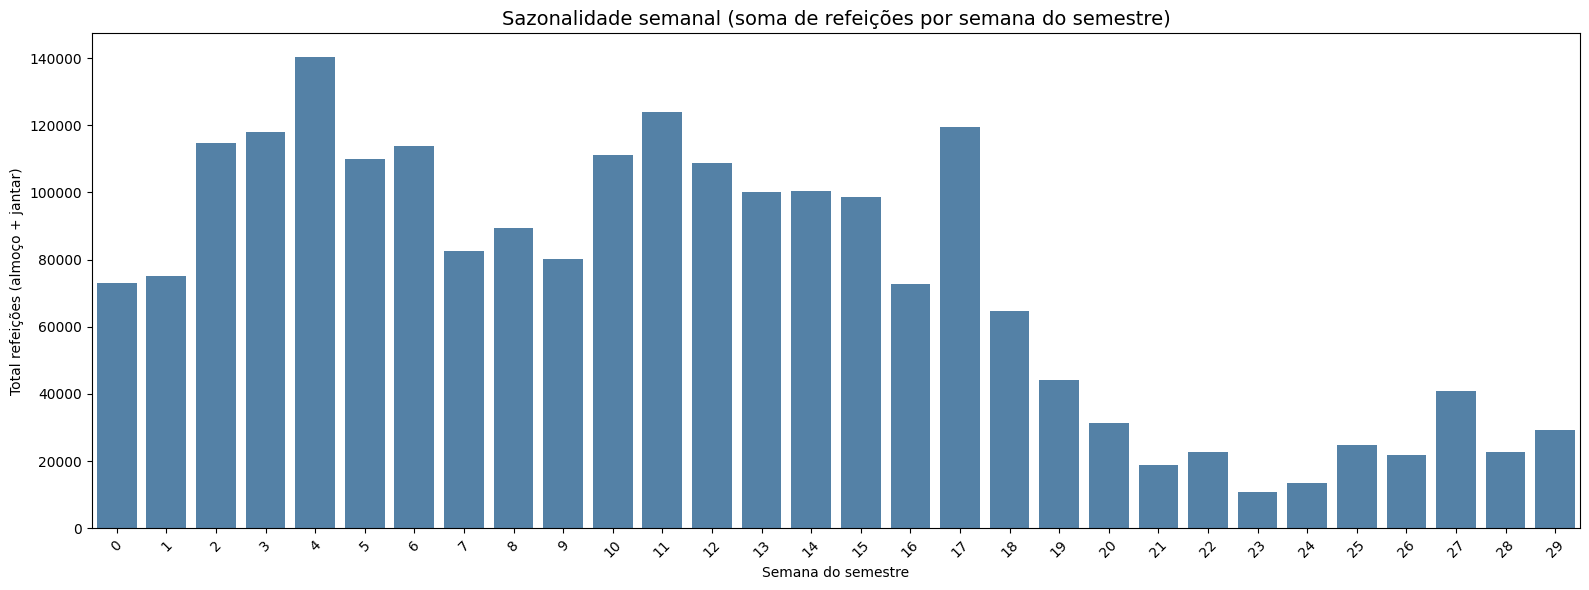

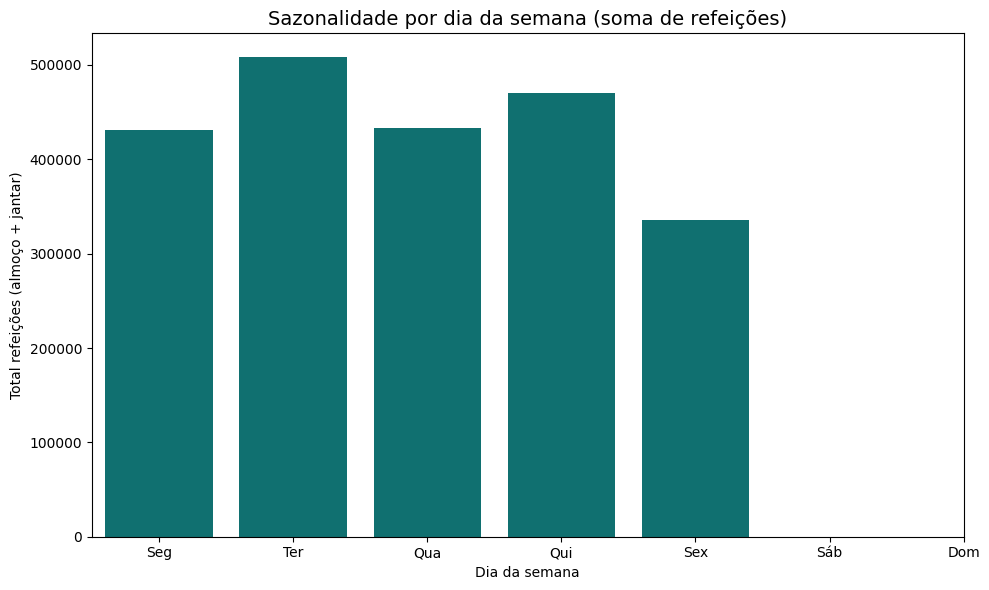

In [42]:
import seaborn as sns
import matplotlib.pyplot as plt

# criar coluna total de refeições
df_final["total_refeicoes"] = pd.to_numeric(df_final["total_almoco"]) + pd.to_numeric(df_final["total_jantar"], errors='coerce')

# --- Gráfico 1: sazonalidade por semana do semestre ---
df_semana = df_final.groupby("semana_semestre", as_index=False)["total_refeicoes"].sum()

plt.figure(figsize=(16,6))
sns.barplot(
    data=df_semana,
    x="semana_semestre",
    y="total_refeicoes",
    color="steelblue"
)
plt.title("Sazonalidade semanal (soma de refeições por semana do semestre)", fontsize=14)
plt.ylabel("Total refeições (almoço + jantar)")
plt.xlabel("Semana do semestre")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# --- Gráfico 2: sazonalidade por dia da semana ---
dias = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
df_dia = df_final.groupby("dia_semana", as_index=False)["total_refeicoes"].sum()

plt.figure(figsize=(10,6))
sns.barplot(
    data=df_dia,
    x="dia_semana",
    y="total_refeicoes",
    color="teal"
)
plt.title("Sazonalidade por dia da semana (soma de refeições)", fontsize=14)
plt.ylabel("Total refeições (almoço + jantar)")
plt.xlabel("Dia da semana")
plt.xticks(ticks=range(7), labels=dias)
plt.tight_layout()
plt.show()


Variáveis

- date - [datetime64(ns)]
- prato_almoco_normal - [string]
- total_almoco - [numerico]
- prato_jantar_normal	- [string]
- total_jantar - [numerico]
- restaurante  - [RU/RA/RS]
- chuva_almoco - [numérico]
- chuva_janta  - [numérico]
- dia_semana - [0/1/2/3/4] -> [Segunda, Terça, Quarta, Quinta, Sexta]
- semana_semestre - [numérico]


# Gráficos de análise das variáveis


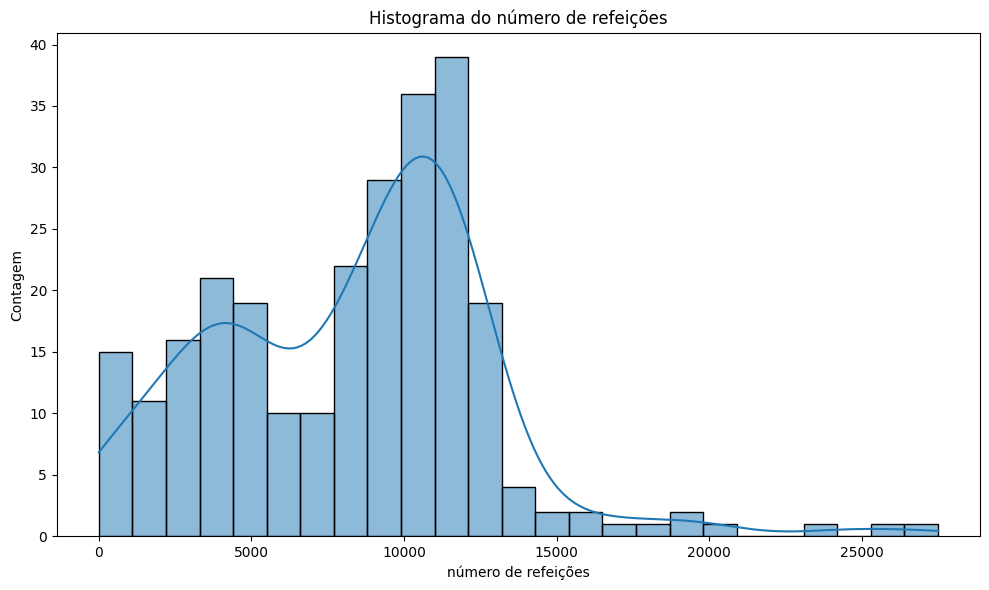

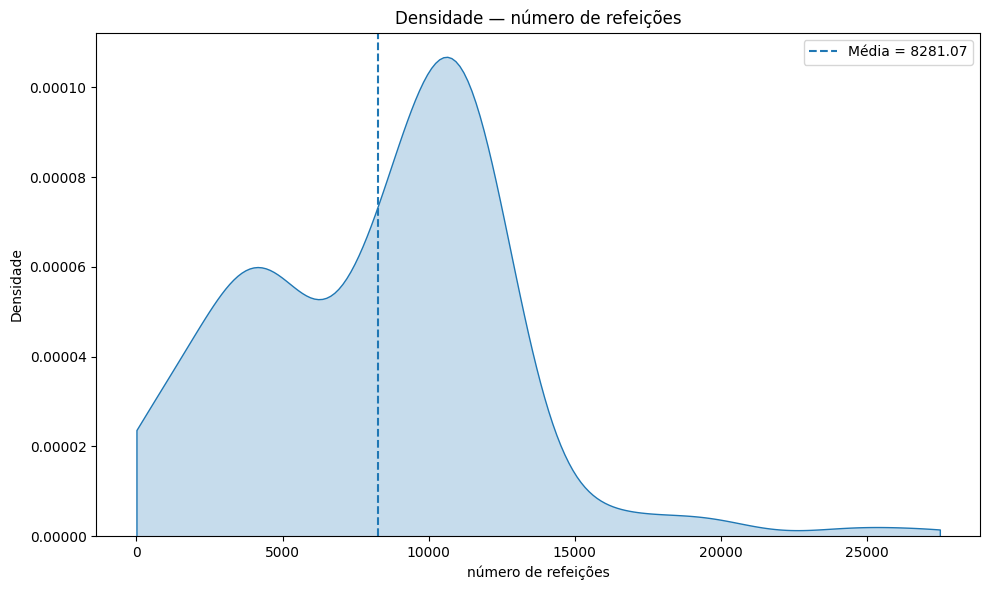

In [43]:
df_final_total_restaurantes = df_final.groupby("date")["total_refeicoes"].sum()

# Histograma
plt.figure(figsize=(10,6))
sns.histplot(df_final_total_restaurantes, bins=25, kde=True)   # kde=True sobrepõe a densidade
plt.title('Histograma do número de refeições')
plt.xlabel('número de refeições')
plt.ylabel('Contagem')
plt.tight_layout()
plt.show()

# Densidade
plt.figure(figsize=(10,6))
sns.kdeplot(data=df_final_total_restaurantes, fill=True, bw_adjust=1, cut=0)
mean = df_final_total_restaurantes.mean()
plt.axvline(mean, linestyle='--', linewidth=1.5, label=f'Média = {mean:.2f}')

plt.title('Densidade — número de refeições')
plt.xlabel('número de refeições')
plt.ylabel('Densidade')
plt.legend()
plt.tight_layout()
plt.show()

In [44]:
# cópia por segurança
df_analise_descriva = df_final.copy()

# colunas a remover: apenas 'restaurante' (não removemos os totais)
cols_to_drop = ['restaurante']
date_col = 'date'
y_col = 'total_refeicoes'

# 1) remove colunas indesejadas (sem tocar nos totais)
df2 = df_analise_descriva.drop(columns=cols_to_drop, errors='ignore')

# garantir que date existe e é datetime
if date_col not in df2.columns:
    raise KeyError(f"Coluna de data '{date_col}' não encontrada. Colunas disponíveis: {list(df2.columns)}")
df2[date_col] = pd.to_datetime(df2[date_col], errors='coerce')

# função que retorna o valor mais frequente (mode) de uma Series
def most_common(s):
    s = s.dropna()
    if s.empty:
        return np.nan
    m = s.mode()
    return m.iloc[0]

# 2) construir dicionário de agregação
agg = {}

# sempre que existir, somar esses totais por dia
for tot in ['total_refeicoes', 'total_almoco', 'total_jantar']:
    if tot in df2.columns:
        agg[tot] = 'sum'

# para as demais colunas (exceto date e já definidos totals) usar most_common
for col in df2.columns:
    if col == date_col:
        continue
    if col in agg:  # já definimos agregação para os totais
        continue
    agg[col] = most_common

# 3) agrupar e agregar
df_analise_descriva = df2.groupby(date_col, as_index=False).agg(agg)

# 4) ordenar e resetar índice
df_analise_descriva = df_analise_descriva.sort_values(date_col).reset_index(drop=True)

print("Agregação completa. Formato resultante:", df_analise_descriva.shape)
df_analise_descriva.head()

Agregação completa. Formato resultante: (263, 12)


,date,total_refeicoes,total_almoco,total_jantar,prato_almoco_normal,prato_almoco_vegano,prato_jantar_normal,prato_jantar_vegano,dia_semana,semana_semestre,chuva_almoco,chuva_janta
0,2024-07-29,5007.0,3101.0,1906.0,CARNE VERMELHA,PTS,PORCO,OUTROS VEGANO,0,0,0.0,0.0
1,2024-07-30,6212.0,3638.0,2574.0,FRANGO,FEIJAO BRANCO,STROGONOFES,STROGONOFF VEGANO,1,0,0.0,0.0
2,2024-08-01,7424.0,4618.0,2806.0,CARNE VERMELHA,OUTROS VEGANO,PORCO,SOJA,3,0,0.0,0.0
3,2024-08-02,7255.0,4442.0,2813.0,CARNE VERMELHA,GRAO DE BICO,SOBRECOXA,FEIJAO BRANCO,4,0,0.0,0.0
4,2024-08-05,11207.0,6910.0,4297.0,PORCO,GRAO DE BICO,CARNE VERMELHA,FEIJAO BRANCO,0,1,0.0,0.0


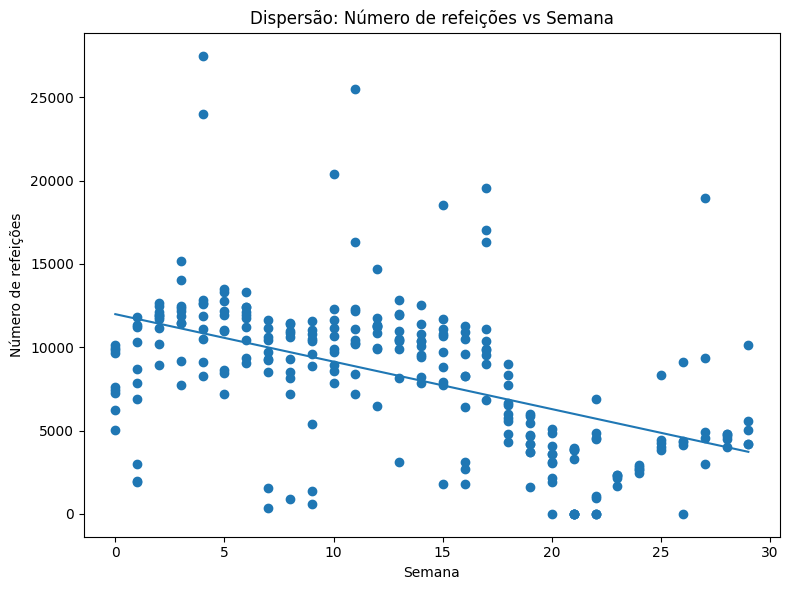

In [45]:
df = df_analise_descriva.copy()

x = pd.to_numeric(df['semana_semestre'], errors='coerce')
y = pd.to_numeric(df['total_refeicoes'], errors='coerce')
mask = x.notna() & y.notna()
x = x[mask]; y = y[mask]

m, b = np.polyfit(x, y, 1)
x_sorted = np.linspace(x.min(), x.max(), 200)
y_fit = m * x_sorted + b

plt.figure(figsize=(8,6))
plt.scatter(x, y)
plt.plot(x_sorted, y_fit)
plt.xlabel('Semana')
plt.ylabel('Número de refeições')
plt.title('Dispersão: Número de refeições vs Semana')
plt.grid(False)
plt.tight_layout()
plt.show()

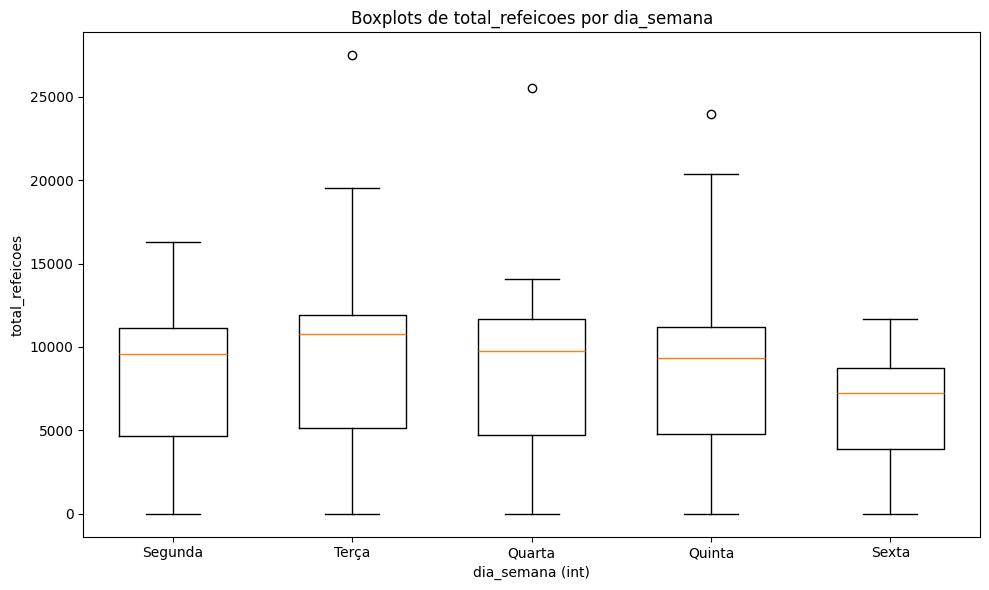

In [46]:
df = df_analise_descriva.copy()

day_col = 'dia_semana'
tot_col = 'total_refeicoes'

df[day_col] = pd.to_numeric(df[day_col], errors='coerce')
df[tot_col] = pd.to_numeric(df[tot_col], errors='coerce')
df_clean = df.dropna(subset=[day_col, tot_col])

# agrupa e ordena as categorias de dia
groups = df_clean.groupby(day_col)[tot_col].apply(list)
days = sorted(groups.index)
data = [groups.loc[d] for d in days]

# --- plot (substituir o bloco de plot existente por este) ---
plt.figure(figsize=(10,6))
ax = plt.gca()
ax.set_facecolor('white')   # garante fundo branco
ax.grid(False)              # sem linhas de grade

bp = ax.boxplot(data, positions=range(len(days)), widths=0.6, patch_artist=False, showfliers=True)

ax.set_xticks(range(len(days)))
ax.set_xticklabels(days)
ax.set_xlabel('dia_semana (int)')
ax.set_ylabel('total_refeicoes')
ax.set_title('Boxplots de total_refeicoes por dia_semana')
ax.set_xticklabels(["Segunda", "Terça", "Quarta", "Quinta", "Sexta"])
plt.tight_layout()
plt.show()

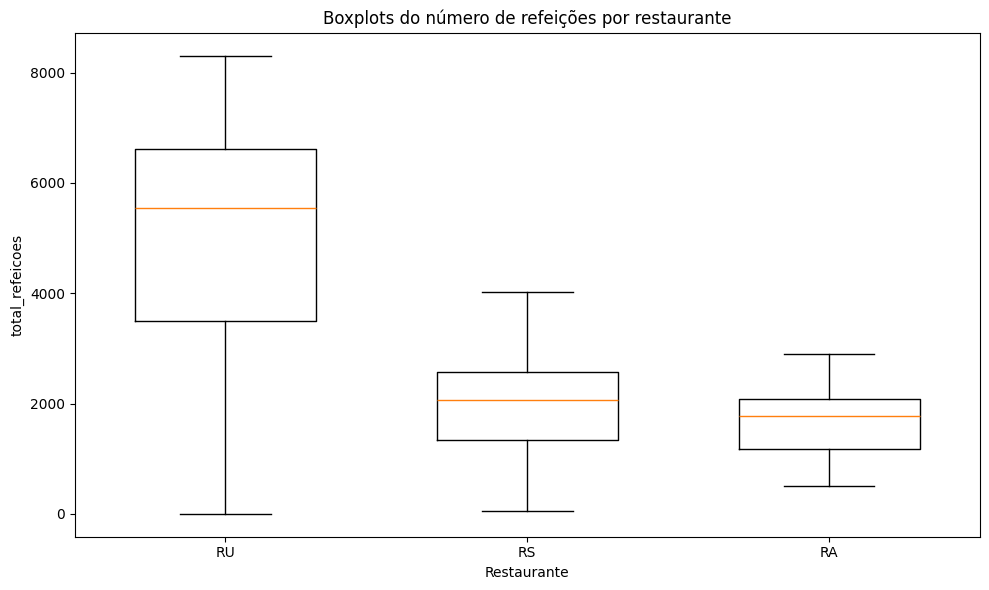

In [47]:
df = df_final.copy()

rest_col = 'restaurante'
tot_col = 'total_refeicoes'

# garantir numérico e remover NA
df[tot_col] = pd.to_numeric(df[tot_col], errors='coerce')
df_clean = df.dropna(subset=[rest_col, tot_col])

# agrupa por restaurante (assume que existem exatamente RU, RS, RA)
groups = df_clean.groupby(rest_col)[tot_col].apply(list)
restaurants = ['RU', 'RS', 'RA']
data = [groups.loc[r] for r in restaurants]

# --- plot (mesmo estilo do seu exemplo) ---
plt.figure(figsize=(10,6))
ax = plt.gca()
ax.set_facecolor('white')   # garante fundo branco
ax.grid(False)              # sem linhas de grade

bp = ax.boxplot(data, positions=range(len(restaurants)), widths=0.6,
                patch_artist=False, showfliers=True)

ax.set_xticks(range(len(restaurants)))
ax.set_xticklabels(restaurants)
ax.set_xlabel('Restaurante')
ax.set_ylabel('total_refeicoes')
ax.set_title('Boxplots do número de refeições por restaurante')

plt.tight_layout()
plt.show()


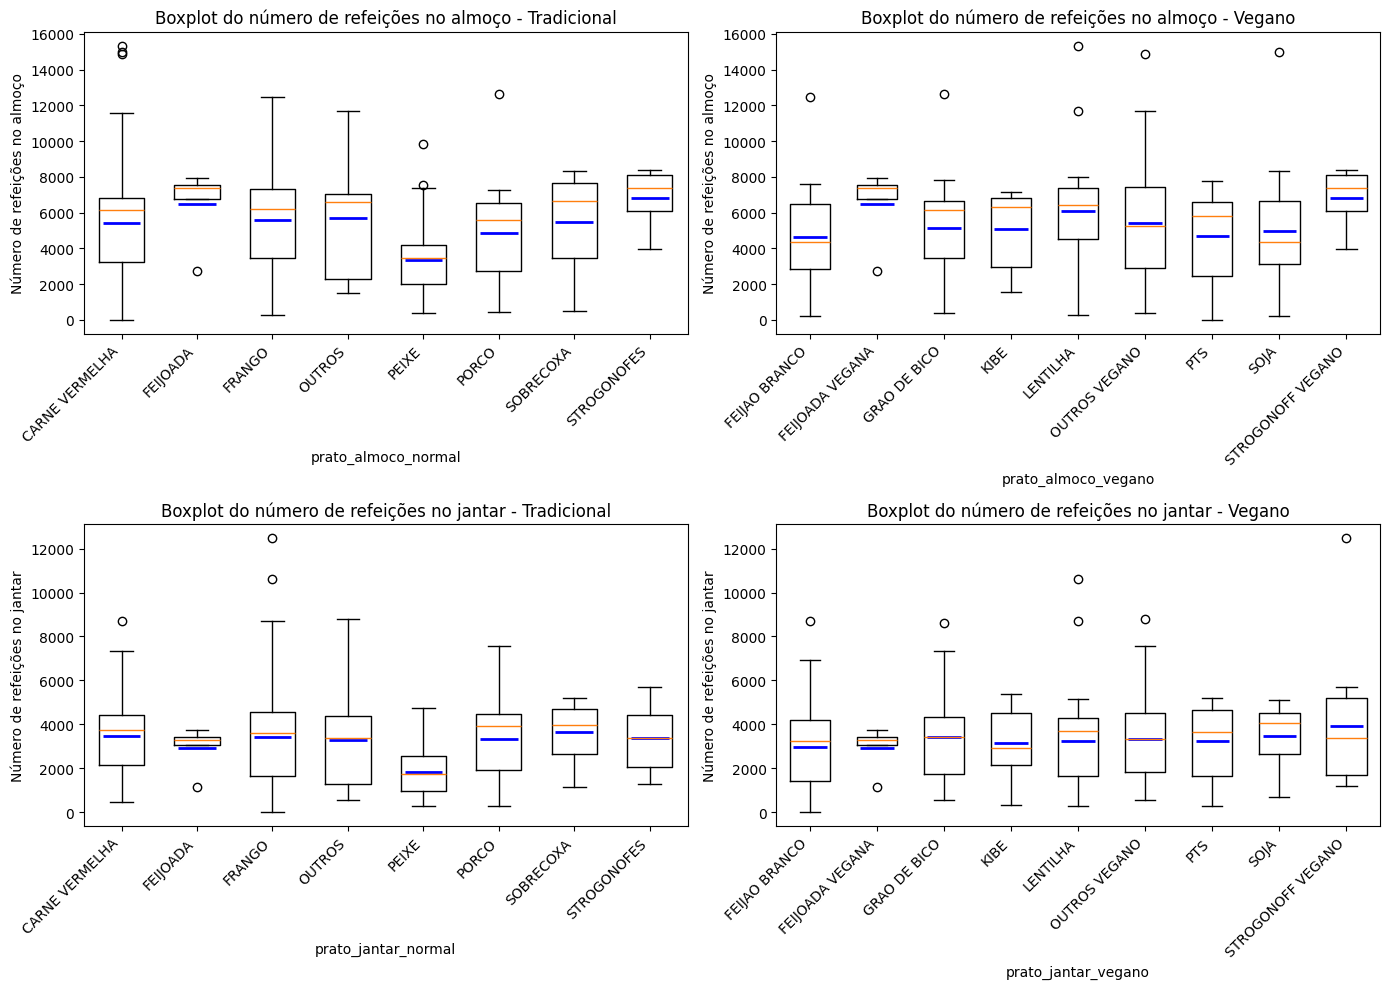

In [48]:
df = df_analise_descriva.copy()
vars_cat = ['prato_almoco_normal', 'prato_almoco_vegano', 'prato_jantar_normal', 'prato_jantar_vegano']

# garantir tipos das categorias
for v in vars_cat:
    df[v] = df[v].astype('category')

# converter ambas as colunas de total (se não existirem, cria série vazia)
df['total_almoco'] = pd.to_numeric(df.get('total_almoco', pd.Series(dtype=float)), errors='coerce')
df['total_jantar'] = pd.to_numeric(df.get('total_jantar', pd.Series(dtype=float)), errors='coerce')

# --- plot: 4 subplots (2x2) ---
fig, axes = plt.subplots(2, 2, figsize=(14,10))
axes = axes.ravel()

for i, var in enumerate(vars_cat):
    ax = axes[i]
    ax.set_facecolor('white')
    ax.grid(False)

    # escolhe a variável y conforme o nome do prato
    if 'jantar' in var:
        tot_col = 'total_jantar'
        ylabel = 'Número de refeições no jantar'
        meal = 'jantar'
    else:
        tot_col = 'total_almoco'
        ylabel = 'Número de refeições no almoço'
        meal = 'almoço'

    # determina se é vegano ou normal
    kind = 'Vegano' if 'vegano' in var else 'Tradicional'

    # monta título no formato pedido
    title = f"Boxplot do número de refeições no {meal} - {kind}"

    # prepara dados apenas com linhas válidas para a categoria e para o total correspondente
    df_plot = df.dropna(subset=[var, tot_col])

    # preserva a ordem natural das categorias, mas só inclui as que têm dados
    categories = [c for c in df[var].cat.categories if df_plot[var].eq(c).any()]

    if len(categories) == 0:
        ax.text(0.5, 0.5, 'Sem dados', ha='center', va='center')
        ax.set_title(title)
        continue

    data = [df_plot.loc[df_plot[var] == cat, tot_col].values for cat in categories]

    # desenha boxplots lado a lado
    bp = ax.boxplot(data, positions=range(len(categories)), widths=0.6,
                    patch_artist=False, showfliers=True)
    # calcular médias por categoria e desenhar uma pequena linha azul sobre cada box
    means = [arr.mean() if len(arr) > 0 else np.nan for arr in data]
    for xi, mu in enumerate(means):
      if not np.isnan(mu):
        ax.hlines(mu, xi - 0.25, xi + 0.25, colors='blue', linewidth=2)
    ax.set_xticks(range(len(categories)))
    ax.set_xticklabels(categories, rotation=45, ha='right')
    ax.set_title(title)
    ax.set_xlabel(var)
    ax.set_ylabel(ylabel)

plt.tight_layout()
plt.show()


#Dados faltantes

In [49]:
df_final.head(20)

,date,prato_almoco_normal,prato_almoco_vegano,total_almoco,prato_jantar_normal,prato_jantar_vegano,total_jantar,restaurante,dia_semana,semana_semestre,chuva_almoco,chuva_janta,total_refeicoes
0,2024-07-29,CARNE VERMELHA,PTS,1919.0,PORCO,OUTROS VEGANO,1346.0,RU,0,0,0.0,0.0,3265.0
1,2024-07-29,CARNE VERMELHA,PTS,643.0,PORCO,OUTROS VEGANO,326.0,RA,0,0,0.0,0.0,969.0
2,2024-07-29,CARNE VERMELHA,PTS,539.0,PORCO,OUTROS VEGANO,234.0,RS,0,0,0.0,0.0,773.0
3,2024-07-30,FRANGO,FEIJAO BRANCO,658.0,STROGONOFES,STROGONOFF VEGANO,337.0,RS,1,0,0.0,0.0,995.0
4,2024-07-30,FRANGO,FEIJAO BRANCO,2271.0,STROGONOFES,STROGONOFF VEGANO,1780.0,RU,1,0,0.0,0.0,4051.0
5,2024-07-30,FRANGO,FEIJAO BRANCO,709.0,STROGONOFES,STROGONOFF VEGANO,457.0,RA,1,0,0.0,0.0,1166.0
6,2024-08-01,CARNE VERMELHA,OUTROS VEGANO,985.0,PORCO,SOJA,490.0,RA,3,0,0.0,0.0,1475.0
7,2024-08-01,CARNE VERMELHA,OUTROS VEGANO,2773.0,PORCO,SOJA,1917.0,RU,3,0,0.0,0.0,4690.0
8,2024-08-01,CARNE VERMELHA,OUTROS VEGANO,860.0,PORCO,SOJA,399.0,RS,3,0,0.0,0.0,1259.0
9,2024-08-02,CARNE VERMELHA,GRAO DE BICO,780.0,SOBRECOXA,FEIJAO BRANCO,410.0,RS,4,0,0.0,0.0,1190.0


In [50]:
# Número de linhas
num_linhas = df_final.shape[0]
print(f"O DataFrame df_final tem {num_linhas} linhas.")


O DataFrame df_final tem 843 linhas.


In [51]:
# Contar valores faltantes por coluna
valores_faltantes = df_final.isna().sum()

# Exibir o resultado
print("Valores faltantes por coluna:")
print(valores_faltantes)


Valores faltantes por coluna:
date                    0
prato_almoco_normal     0
prato_almoco_vegano     0
total_almoco           88
prato_jantar_normal    39
prato_jantar_vegano    39
total_jantar           97
restaurante             0
dia_semana              0
semana_semestre         0
chuva_almoco            0
chuva_janta             0
total_refeicoes        98
dtype: int64


In [52]:
# Criar um novo DataFrame sem valores faltantes
df_limpo = df_final.dropna()

# Exibir algumas informações do novo DataFrame
print("Dimensões do novo DataFrame:", df_limpo.shape)
print("Primeiras linhas do DataFrame limpo:")
print(df_limpo.head())


Dimensões do novo DataFrame: (740, 13)
Primeiras linhas do DataFrame limpo:
        date prato_almoco_normal prato_almoco_vegano  total_almoco  \
0 2024-07-29      CARNE VERMELHA                 PTS        1919.0   
1 2024-07-29      CARNE VERMELHA                 PTS         643.0   
2 2024-07-29      CARNE VERMELHA                 PTS         539.0   
3 2024-07-30              FRANGO       FEIJAO BRANCO         658.0   
4 2024-07-30              FRANGO       FEIJAO BRANCO        2271.0   

  prato_jantar_normal prato_jantar_vegano  total_jantar restaurante  \
0               PORCO       OUTROS VEGANO        1346.0          RU   
1               PORCO       OUTROS VEGANO         326.0          RA   
2               PORCO       OUTROS VEGANO         234.0          RS   
3         STROGONOFES   STROGONOFF VEGANO         337.0          RS   
4         STROGONOFES   STROGONOFF VEGANO        1780.0          RU   

   dia_semana  semana_semestre  chuva_almoco  chuva_janta  total_refeicoes  

In [53]:
# Número de linhas
num_linhas = df_limpo.shape[0]
print(f"O DataFrame df_final tem {num_linhas} linhas.")


O DataFrame df_final tem 740 linhas.


In [54]:
df_final.to_csv('df_limpo.csv', index=False)



In [55]:
from google.colab import files
files.download('df_limpo.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#Parte2

Objetivo: Prever o número de usuários no sistema de RU da Unicamp a cada dia da semana.

Utilize dois algoritmos de aprendizado supervisionado, com diferentes graus de interpretabilidade, para fazer a previsão do número de usuários dos RUs da Unicamp a cada dia.

Os resultados devem ser entregues em um relatório de até 9 páginas, a descrição do banco de dados feita na Parte I deve estar presente aqui. Pode ser mais resumida, mas deve estar presente.

Obs 1: Deve ser apresentado a parte teórica de cada um dos algoritmos utilizados, a motivação para a escolha deles, quais parâmetros foram usados, quais dados foram usados como treinamento e quais como teste.

Obs 2: A discussão e conclusão são essenciais para um artigo, devem discutir quais são os resultados encontrados pelos algoritmos e a interpretação deles para o problema abordado.

Obs 3: Deixo um artigo científico sobre como fazer a discussão de resultados de uma pesquisa.

In [ ]:
# ==========================================================
# PREVISÃO DE USUÁRIOS NOS RESTAURANTES UNIVERSITÁRIOS (RU)
# ==========================================================
# Objetivo: prever o número total de refeições (total_refeicoes)
# a partir de informações sobre o cardápio, o restaurante,
# o dia da semana e as condições de chuva.
# ==========================================================

# --- IMPORTAÇÃO DAS BIBLIOTECAS ---
import sklearn
import pandas as pd
import numpy as np

# Modelagem e pré-processamento
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Modelos
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Avaliação
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ==========================================================
# 1. CARREGAR OS DADOS
# ==========================================================

df = df_limpo.copy()

print("Valores ausentes por coluna:")
print(df.isna().sum())

df = df.dropna(subset=['total_refeicoes'])


# ==========================================================
# 2. SELEÇÃO DAS VARIÁVEIS
# ==========================================================

X = df[['restaurante', 'dia_semana',
        'prato_almoco_normal', 'prato_almoco_vegano',
        'prato_jantar_normal', 'prato_jantar_vegano',
        'chuva_almoco', 'chuva_janta']]

y = df['total_refeicoes']


# ==========================================================
# 3. DIVISÃO TREINO/TESTE
# ==========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


# ==========================================================
# 4. PRÉ-PROCESSAMENTO
# ==========================================================

cat_features = ['restaurante', 'prato_almoco_normal',
                'prato_almoco_vegano', 'prato_jantar_normal',
                'prato_jantar_vegano', 'dia_semana']

num_features = ['chuva_almoco', 'chuva_janta']

preprocess = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features),
        ('num', 'passthrough', num_features)
    ]
)


# ==========================================================
# 6. RANDOM FOREST + GRIDSEARCHCV
# ==========================================================

pipe_rf = Pipeline([
    ('preprocess', preprocess),
    ('model', RandomForestRegressor(
        n_estimators=1000,
        criterion='squared_error',
        max_depth=None,
        min_samples_split=8,
        min_samples_leaf=1,
        max_features='sqrt',
        bootstrap=True,
        n_jobs=-1,
        random_state=42
    ))
])

param_grid = {
    'model__n_estimators': [200, 500, 1000],
    'model__max_depth': [None, 10, 20, 40],
    'model__min_samples_split': [2, 4, 8],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': ['sqrt', 0.5, None],
    'model__bootstrap': [True, False],
    'model__ccp_alpha': [0.0, 1e-4, 1e-3]
}

grid_search = GridSearchCV(
    estimator=pipe_rf,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    verbose=2,
    refit=True
)

grid_search.fit(X_train, y_train)

best_params = grid_search.best_params_
best_score = grid_search.best_score_
best_estimator = grid_search.best_estimator_

print("\nMelhores parâmetros encontrados:")
print(best_params)


# Previsões no teste
y_pred_rf = best_estimator.predict(X_test)


# ==========================================================
# 7. AVALIAÇÃO DO MODELO
# ==========================================================

def avaliar_modelo(y_true, y_pred, nome_modelo):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    print(f"\n🔹 {nome_modelo}")
    print(f"MAE  (Erro Médio Absoluto): {mae:.2f}")
    print(f"RMSE (Raiz do EQM): {rmse:.2f}")
    print(f"R²   (Coeficiente de Determinação): {r2:.3f}")


avaliar_modelo(y_test, y_pred_rf, "Random Forest (GridSearchCV)")


# ==========================================================
# 8. IMPORTÂNCIA DAS VARIÁVEIS
# ==========================================================

rf_model = best_estimator.named_steps['model']
ohe = best_estimator.named_steps['preprocess'].named_transformers_['cat']

feature_names = list(ohe.get_feature_names_out(cat_features)) + num_features

importances = pd.DataFrame({
    'Variável': feature_names,
    'Importância': rf_model.feature_importances_
}).sort_values(by='Importância', ascending=False)

print("\n🔸 10 variáveis mais importantes (Random Forest):")
print(importances.head(10))


Valores ausentes por coluna:
date                   0
prato_almoco_normal    0
prato_almoco_vegano    0
total_almoco           0
prato_jantar_normal    0
prato_jantar_vegano    0
total_jantar           0
restaurante            0
dia_semana             0
semana_semestre        0
chuva_almoco           0
chuva_janta            0
total_refeicoes        0
dtype: int64
Fitting 5 folds for each of 1944 candidates, totalling 9720 fits


In [ ]:
# ==========================================================
# PREVISÃO DE USUÁRIOS NOS RESTAURANTES UNIVERSITÁRIOS (RU)
# ==========================================================
# Objetivo: prever o número total de refeições (total_refeicoes)
# a partir de informações sobre o cardápio, o restaurante,
# o dia da semana e as condições de chuva.
# ==========================================================

# --- IMPORTAÇÃO DAS BIBLIOTECAS ---
import sklearn
import pandas as pd
import numpy as np

# Modelagem e pré-processamento
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Modelos
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Avaliação
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ==========================================================
# 1. CARREGAR OS DADOS
# ==========================================================

# Aqui assumimos que o DataFrame já está carregado como df_final
df = df_limpo.copy()

# --- VERIFICAR SE EXISTEM VALORES FALTANTES ---
print("Valores ausentes por coluna:")
print(df.isna().sum())

# --- REMOVER LINHAS COM y (variável alvo) FALTANTE ---
df = df.dropna(subset=['total_refeicoes'])

# ==========================================================
# 2. SELEÇÃO DAS VARIÁVEIS
# ==========================================================
# Variáveis explicativas (features)
X = df[['restaurante', 'dia_semana',
        'prato_almoco_normal', 'prato_almoco_vegano',
        'prato_jantar_normal', 'prato_jantar_vegano',
        'chuva_almoco', 'chuva_janta']]

# Variável alvo (target)
y = df['total_refeicoes']

# ==========================================================
# 3. DIVISÃO ENTRE TREINO E TESTE
# ==========================================================
# 80% dos dados para treino e 20% para teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ==========================================================
# 4. PRÉ-PROCESSAMENTO DOS DADOS
# ==========================================================
# As variáveis categóricas precisam ser transformadas em números.
# Usamos OneHotEncoder para criar variáveis binárias (0/1) para cada categoria.

# Variáveis categóricas
cat_features = ['restaurante', 'prato_almoco_normal',
                'prato_almoco_vegano', 'prato_jantar_normal',
                'prato_jantar_vegano', 'dia_semana']

# Variáveis numéricas (mantidas como estão)
#num_features = ['dia_semana', 'chuva_almoco', 'chuva_janta']
num_features = ['chuva_almoco', 'chuva_janta']

# Criamos o transformador que aplica o OneHotEncoder nas categóricas
preprocess = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features),
        ('num', 'passthrough', num_features)
    ]
)

# ==========================================================
# 6. MODELO 2 — RANDOM FOREST REGRESSOR
# ==========================================================
# Modelo mais complexo, captura relações não lineares e interações.

pipe_rf = Pipeline([
    ('preprocess', preprocess),
    ('model', RandomForestRegressor(
        n_estimators=1000,
        criterion='squared_error',
        max_depth=None,
        min_samples_split=8,
        min_samples_leaf=1,
        min_weight_fraction_leaf=0.0,
        max_features='sqrt',       # corrigido aqui
        max_leaf_nodes=None,
        min_impurity_decrease=0.0,
        bootstrap=True,
        oob_score=False,
        n_jobs=-1,
        random_state=42,
        verbose=0,
        warm_start=False,
        ccp_alpha=0.0,
        max_samples=None
    ))
])

param_grid = {
'model__n_estimators': [200, 500, 1000],
'model__max_depth': [None, 10, 20, 40],
'model__min_samples_split': [2, 4, 8],
'model__min_samples_leaf': [1, 2, 4],
'model__max_features': ['sqrt', 0.5, None],
'model__bootstrap': [True, False],
'model__ccp_alpha': [0.0, 1e-4, 1e-3]
}


grid_search = GridSearchCV(
estimator=pipe_rf,
param_grid=param_grid,
cv=5,
scoring='neg_mean_squared_error',
n_jobs=-1,
verbose=2,
refit=True
)


# --- Treinamento com GridSearchCV ---
# Isso executa a validação cruzada para cada combinação de parâmetros
grid_search.fit(X_train, y_train)


# --- Resultados ---
best_params = grid_search.best_params_
best_score = grid_search.best_score_
best_estimator = grid_search.best_estimator_


# Previsões no conjunto de teste com o melhor modelo encontrado
y_pred_gs = best_estimator.predict(X_test)

# Treinamento
pipe_rf.fit(X_train, y_train)

# ==========================================================
# 7. AVALIAÇÃO DOS MODELOS
# ==========================================================
def avaliar_modelo(y_true, y_pred, nome_modelo):
    """
    Função para calcular e exibir as principais métricas de regressão.
    """
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    print(f"\n🔹 {nome_modelo}")
    print(f"MAE  (Erro Médio Absoluto): {mae:.2f}")
    print(f"RMSE (Raiz do Erro Quadrático Médio): {rmse:.2f}")
    print(f"R²   (Coeficiente de Determinação): {r2:.3f}")

# Avaliar ambos os modelos
avaliar_modelo(y_test, y_pred_rf, "Random Forest")

# ==========================================================
# 8. IMPORTÂNCIA DAS VARIÁVEIS (apenas para o Random Forest)
# ==========================================================
rf_model = pipe_rf.named_steps['model']
ohe = pipe_rf.named_steps['preprocess'].named_transformers_['cat']

# Nomes das variáveis após o OneHotEncoding
feature_names = list(ohe.get_feature_names_out(cat_features)) + num_features

# Criação do DataFrame com importâncias
importances = pd.DataFrame({
    'Variável': feature_names,
    'Importância': rf_model.feature_importances_
})

# Ordenar pela importância decrescente
importances = importances.sort_values(by='Importância', ascending=False)

print("\n🔸 10 variáveis mais importantes (Random Forest):")
print(importances.head(10))



In [ ]:
# ==========================================================
# 9. GRÁFICO DE DISPERSÃO: Observado vs Previsto
# ==========================================================
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))
sns.scatterplot(x=y_test, y=y_pred_rf, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         color='red', linestyle='--', linewidth=2)  # linha y=x
plt.xlabel("Total de Refeições Observadas")
plt.ylabel("Total de Refeições Previstas (Random Forest)")
plt.title("Dispersão: Observado vs Previsto")
plt.grid(True)
plt.show()


In [ ]:
# ==========================================================
# Variáveis explicativas (features)
X = df[['restaurante', 'dia_semana',
        'prato_almoco_normal', 'prato_almoco_vegano',
        'prato_jantar_normal', 'prato_jantar_vegano',
        'chuva_almoco', 'chuva_janta']]

# Variável alvo (target)
y = df['total_refeicoes']
# ==========================================================

# ==========================================================
# 3. DIVISÃO ENTRE TREINO E TESTE
# ==========================================================
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Identificação das colunas categóricas e numéricas
cat_features = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# ==========================================================
# 4. PRÉ-PROCESSAMENTO
# ==========================================================
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocess = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features),
    ('num', 'passthrough', num_features)
])

X_train_enc = preprocess.fit_transform(X_train)
X_test_enc = preprocess.transform(X_test)

# ==========================================================
# 5. TREINO DO GAUSSIAN NAIVE BAYES
# ==========================================================
from sklearn.naive_bayes import GaussianNB
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

gnb = GaussianNB()
gnb.fit(X_train_enc.toarray(), y_train)  # GaussianNB precisa de array denso

# ==========================================================
# 6. PREVISÕES E AVALIAÇÃO
# ==========================================================
y_pred_nb = gnb.predict(X_test_enc.toarray())

mae = mean_absolute_error(y_test, y_pred_nb)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_nb))
r2 = r2_score(y_test, y_pred_nb)

print("\n🔹 Métricas GaussianNB:")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.3f}")




In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- Garantir que a coluna 'date' é do tipo datetime ---
df['date'] = pd.to_datetime(df['date'])

# --- 1. Série Temporal ---
plt.figure(figsize=(12,6))
sns.lineplot(data=df, x='date', y='total_refeicoes', marker='o', color='blue')
plt.title("Série Temporal - Total de Refeições")
plt.xlabel("Data")
plt.ylabel("Total de Refeições")
plt.grid(True)
plt.show()

# --- 2. Gráfico de Dispersão: Observado vs Previsto (Random Forest) ---
plt.figure(figsize=(10,6))
sns.scatterplot(x=y_test, y=y_pred_rf, alpha=0.6, color='green', label='Random Forest')

# Linha de referência y=x
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         color='red', linestyle='--', linewidth=2, label='Previsão Perfeita')

plt.title("Dispersão: Observado vs Previsto")
plt.xlabel("Total de Refeições Observadas")
plt.ylabel("Total de Refeições Previstas")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
#### to fazendo rede neural
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import GridSearchCV, KFold
from scipy import sparse

# ==========================================================
# Variáveis explicativas (features)
X = df[['restaurante', 'dia_semana',
        'prato_almoco_normal', 'prato_almoco_vegano',
        'prato_jantar_normal', 'prato_jantar_vegano',
        'chuva_almoco', 'chuva_janta']]

# Variável alvo (target)
y = df['total_refeicoes']

# ==========================================================
# 4. PRÉ-PROCESSAMENTO
# ==========================================================
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocess = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features),
    ('num', 'passthrough', num_features)
])

X_train_enc = preprocess.fit_transform(X_train)
X_test_enc = preprocess.transform(X_test)

if sparse.issparse(X_train_enc):
    X_train_enc = X_train_enc.toarray()
if sparse.issparse(X_test_enc):
    X_test_enc = X_test_enc.toarray()

# ==========================================================
# 5. HIPERPARAMETROS
# ==========================================================

param_grid = {
    'hidden_layer_sizes': ((32,16),(8,32,16)),
    'alpha': [1e-05,1e-06],
    'learning_rate_init': [0.05, 0.001, 0.0005],
    'batch_size': [64,128],
    'activation': ['relu']
}

mlp = MLPRegressor(max_iter=500, random_state=1)


cv = KFold(n_splits= 5, shuffle=True, random_state=42)

grid = GridSearchCV(
    estimator=mlp,
    param_grid=param_grid,
    scoring='neg_mean_squared_error',
    cv=cv,
    n_jobs=-1,
    verbose=2,
    refit=True
)

# rodar busca no X_train_enc (já pré-processado) e y_train
grid.fit(X_train_enc, y_train)

# resultados principais
print("Melhores hiperparâmetros:", grid.best_params_)
print("Melhor score CV (neg MSE):", grid.best_score_)
print("Melhor RMSE médio CV:", np.sqrt(-grid.best_score_))

# avaliar no conjunto de teste (pré-processado)
best_model = grid.best_estimator_
y_pred_rn = best_model.predict(X_test_enc)
mse_test = mean_squared_error(y_test, y_pred_rn)
print("Test RMSE:", np.sqrt(mse_test), "  Test R2:", r2_score(y_test, y_pred_rn))


In [ ]:
# ==========================================================
# 9. GRÁFICO DE DISPERSÃO: Observado vs Previsto
# ==========================================================
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))
sns.scatterplot(x=y_test, y=y_pred_rn, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         color='red', linestyle='--', linewidth=2)  # linha y=x
plt.xlabel("Total de Refeições Observadas")
plt.ylabel("Total de Refeições Previstas (Rede Neural)")
plt.title("Dispersão: Observado vs Previsto")
plt.grid(True)
plt.show()


avaliar_modelo(y_test, y_pred_rn, "Rede Neural")

In [ ]:
y_pred_ens = (y_pred_rf + y_pred_rn)/2
plt.figure(figsize=(8,6))
sns.scatterplot(x=y_test, y=y_pred_ens, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         color='red', linestyle='--', linewidth=2)  # linha y=x
plt.xlabel("Total de Refeições Observadas")
plt.ylabel("Total de Refeições Previstas (Modelo Ensamble)")
plt.title("Dispersão: Observado vs Previsto")
plt.grid(True)
plt.show()


avaliar_modelo(y_test, y_pred_ens, "Modelo Ensamble")

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

# Define limites comuns (pega min/max entre observado e todas as previsões)
all_vals = np.concatenate([y_test,y_pred_ens, y_pred_rf, y_pred_rn])
vmin, vmax = all_vals.min(), all_vals.max()
pad = (vmax - vmin) * 0.03  # pequeno padding visual
lims = (vmin - pad, vmax + pad)

# Lista com pares (y, título) para iterar
plots = [
    (y_pred_ens, "Ensemble"),
    (y_pred_rf,  "Random Forest"),
    (y_pred_rn,  "Rede Neural")
]

for ax, (pred, title) in zip(axes, plots):
    sns.scatterplot(x=y_test, y=pred, ax=ax, s=40, edgecolor='k', alpha=0.7)
    # linha identidade y=x
    ax.plot(lims, lims, linestyle='--', color='red', linewidth=2)
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Total de Refeições Observadas")
    ax.grid(True)

# Ajusta rótulo y só no primeiro eixo (já que sharey=True)
axes[0].set_ylabel("Total de Refeições Previstas")

# Título geral acima dos 3 gráficos
fig.suptitle("Dispersão: Observado vs Previsto (Comparação de Modelos)", fontsize=16)

# Melhor ajuste do layout para o título não sobrepor
fig.tight_layout(rect=[0, 0, 1, 0.93])  # deixa espaço superior para suptitle

#Parte 3

Objetivo: Encontrar cluster, conexões entre os as demandas do RU e as demais variáveis do banco de dados. A ideia é proporcionar dias representativos de consumo, ou seja, com perfis parecidos de consumo.


Utilize pelo menos um algoritmo de aprendizado não-supervisionado. Descreva as métricas de similaridade utilizadas no algoritmo, a análise do número ótimo de clusters e o perfil de cada um dos clusters.

O seu relatório aqui deve ter até 13 páginas e deve conter as discussões e resultados da Parte I e Parte II. O relatório resultante da Parte III é o seu projeto final, é por ele que vocês serão avaliados.


##K-means

In [ ]:
df_limpo.head()

In [ ]:
from sklearn.preprocessing import StandardScaler

# Lista de colunas numéricas (excluindo date e variáveis categóricas)
colunas_numericas = [
    'total_almoco',
    'total_jantar',
    'chuva_almoco',
    'chuva_janta',
    'total_refeicoes'
]

# Inicializa o scaler
scaler = StandardScaler()

# Aplica o scaler apenas nas colunas numéricas
df_limpo[colunas_numericas] = scaler.fit_transform(df_limpo[colunas_numericas])



In [ ]:
df_limpo.head()

In [ ]:
# Garantir que a coluna date está no formato datetime
df_limpo['date'] = pd.to_datetime(df_limpo['date'])

# Separar por restaurante
df_RU = df_limpo[df_limpo['restaurante'] == 'RU'].sort_values(by='date')
df_RS = df_limpo[df_limpo['restaurante'] == 'RS'].sort_values(by='date')
df_RA = df_limpo[df_limpo['restaurante'] == 'RA'].sort_values(by='date')

# (Opcional) Resetar o índice
df_RU = df_RU.reset_index(drop=True)
df_RS = df_RS.reset_index(drop=True)
df_RA = df_RA.reset_index(drop=True)


In [ ]:
print("Número de linhas df_RU:", len(df_RU))
print("Número de linhas df_RS:", len(df_RS))
print("Número de linhas df_RA:", len(df_RA))

In [ ]:
df_RU.head()

In [ ]:
df_RU.to_csv("df_RU.csv", index=False)

from google.colab import files
files.download("df_RU.csv")

In [ ]:
# ============================================================
# PARTE 1 — IMPORTAÇÃO DAS BIBLIOTECAS E SELEÇÃO DAS VARIÁVEIS
# ============================================================

import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Copia o dataframe original
df = df_RU.copy()

# ------------------------------------------------------------
# USAR SOMENTE VARIÁVEIS NUMÉRICAS NORMALIZADAS
# ------------------------------------------------------------
num_cols = [
    "total_almoco",
    "total_jantar",
    "chuva_almoco",
    "chuva_janta",
    "total_refeicoes"
]

# Matriz de treinamento
X = df[num_cols].values


In [ ]:
# ============================================================
# PARTE 2 — ESCOLHA DO NÚMERO ÓTIMO DE CLUSTERS
# ============================================================

inertias = []
sil_scores = []
K_range = range(2, 11)   # testar k de 2 a 10

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)

    # Inércia (método do cotovelo)
    inertias.append(kmeans.inertia_)

    # Silhouette (qualidade da separação)
    sil_scores.append(silhouette_score(X, kmeans.labels_))

# -----------------
# GRAFICO ELBOW
# -----------------
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(K_range, inertias, marker='o')
plt.title("Método do Cotovelo")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inércia")

# -----------------
# GRAFICO SILHOUETTE
# -----------------
plt.subplot(1,2,2)
plt.plot(K_range, sil_scores, marker='o')
plt.title("Silhouette Score")
plt.xlabel("k")
plt.ylabel("Silhouette")

plt.show()

# Melhor k segundo silhouette
best_k = K_range[np.argmax(sil_scores)]
print("Melhor k segundo o Silhouette Score:", best_k)


In [ ]:
# ============================================================
# PARTE 3 — TREINAMENTO DO K-MEANS FINAL
# ============================================================

kmeans_final = KMeans(n_clusters=best_k, random_state=42, n_init=10)

# Ajusta o modelo usando APENAS variáveis numéricas
df["cluster"] = kmeans_final.fit_predict(X)

# Quantos dias ficaram em cada cluster
print("\nDistribuição dos clusters:")
print(df["cluster"].value_counts())


In [ ]:
df

In [ ]:
# ============================================================
# PARTE 4 — PERFIL DE CADA CLUSTER (CENTRÓIDES)
# ============================================================

centroid_df = pd.DataFrame(
    kmeans_final.cluster_centers_,
    columns=num_cols
)

print("\n=== CENTRÓIDES DOS CLUSTERS ===")
display(centroid_df)


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração das colunas
colunas_interesse = [
    'total_almoco',
    'total_jantar',
    'chuva_almoco',
    'chuva_janta',
    'total_refeicoes'
]

# Aumentei o tamanho da figura (figsize) para acomodar as fontes maiores
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(13, 15))

# Achata a matriz de eixos para facilitar o loop
axes = axes.flatten()

for i, col in enumerate(colunas_interesse):
    sns.boxplot(
        x='cluster',
        y=col,
        data=df,
        ax=axes[i],
        palette="viridis",
        hue='cluster',
        legend=False
    )

    # --- CONFIGURAÇÃO DE FONTES MAIORES ---
    # Título do gráfico
    axes[i].set_title(f'Boxplot: {col}', fontsize=18, fontweight='bold', pad=20)

    # Títulos dos eixos (X e Y)
    axes[i].set_xlabel('Cluster', fontsize=15, labelpad=15)
    axes[i].set_ylabel(col, fontsize=15, labelpad=15)

    # Tamanho dos números nos eixos (1, 2, 3... e valores de y)
    axes[i].tick_params(axis='both', which='major', labelsize=16)

# Remover o 6º gráfico (vazio)
fig.delaxes(axes[5])

# Ajusta o layout para evitar cortes
plt.tight_layout()


plt.savefig(
    'boxplots_clusters_ru.png',
    dpi=300,        # Alta resolução (300 pontos por polegada é ótimo para documentos)
    bbox_inches='tight' # Garante que todo o conteúdo (títulos, eixos) caiba no arquivo
)
plt.show()

Para identificar padrões de consumo no Restaurante Universitário (RU), foi aplicado um algoritmo de aprendizado não supervisionado do tipo K-means, utilizando exclusivamente variáveis numéricas previamente normalizadas:
total_almoco, total_jantar, chuva_almoco, chuva_janta e total_refeicoes.

A similaridade entre os dias foi medida por meio da distância euclidiana, que é a métrica padrão do K-means. Quanto menor a distância entre dois registros, mais similares são seus perfis de demanda e de condições ambientais.

A escolha do número ótimo de clusters foi feita por meio do método do Cotovelo (redução do WSS) e do Índice de Silhueta, que juntos indicaram a existência de aproximadamente quatro padrões distintos de comportamento da demanda. Com base nisso, o modelo final foi ajustado com k = 4 clusters.

Os centróides resultantes representam dias típicos para cada grupo e permitem interpretar os perfis de consumo:

Cluster 0 — Dias de Alta Demanda

Caracterizado por valores elevados de total_almoco, total_jantar e total_refeicoes (centróides em torno de 1.65–1.70). Esses dias apresentam baixa precipitação. São dias de grande movimento, típicos de semanas letivas normais.

Cluster 1 — Dias de Baixíssima Demanda

Apresenta valores muito baixos em todas as variáveis (total_refeicoes ≈ 0.06). Representa dias com procura mínima, possivelmente feriados, recessos ou dias com funcionamento parcial.

Cluster 2 — Demanda Moderada e Chuva no Almoço

Possui demanda intermediária e nível de chuva relativamente alto no almoço (chuva_almoco ≈ 0.93). O total de refeições é mediano. Representa dias nos quais a chuva influencia parcialmente a movimentação, sem reduzir drasticamente o consumo.

Cluster 3 — Baixa Demanda com Chuva Extrema

Apresenta chuva_almoco extremamente alta (≈ 13.45), acompanhada de baixa demanda. Esse cluster indica que chuvas muito intensas reduzem significativamente o fluxo de usuários, especialmente no almoço.

##kprototypes

In [ ]:
!pip install kmodes
from kmodes.kprototypes import KPrototypes
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score


In [ ]:
from copy import copy
from kmodes.kprototypes import KPrototypes

# === 1. Criar cópia do dataframe original ===
df2 = df_RU.copy()
df2 = df2.drop(columns=["restaurante"])

# === 2. Variáveis numéricas ===
variaveis_numericas = [
    "total_almoco",
    "total_jantar",
    "total_refeicoes",
    "chuva_almoco",
    "chuva_janta"
]

# === 3. Variáveis categóricas ===
variaveis_categoricas = [
    "dia_semana",
    "semana_semestre",
    "prato_jantar_normal",
    "prato_jantar_vegano",
    "prato_almoco_normal",
    "prato_almoco_vegano"
]

# === 4. Garantir tipos corretos ===
df2[variaveis_numericas] = df2[variaveis_numericas].astype(float)
df2[variaveis_categoricas] = df2[variaveis_categoricas].astype(str)

# === 5. Construir lista final de colunas ===
colunas = variaveis_numericas + variaveis_categoricas

# === 6. Criar matriz X ===
X = df2[colunas].to_numpy()

# === 7. Obter índices das colunas categóricas dentro de X ===
cat_cols_index = [colunas.index(c) for c in variaveis_categoricas]

# (opcional) visualizar para conferir
cat_cols_index



In [ ]:
from kmodes.kprototypes import KPrototypes
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

indices_cat = cat_cols_index
indices_num = [i for i in range(X.shape[1]) if i not in indices_cat]


preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), indices_num), # Padroniza os dados numéricos
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), indices_cat) # OHE nos categóricos
    ],
    remainder='passthrough'
)

X_transformado = preprocessor.fit_transform(X)


# 2. LOOP DE AVALIAÇÃO COM CUSTO E SILHUETA
custos = {}
silhuetas = {} # Novo dicionário para salvar o Silhouette Score

print("=== Avaliando valores de k de 2 até 10 (Custo e Silhueta) ===")

# O loop vai de k=2 a k=10, pois k=1 não é válido para o Coeficiente de Silhueta
for k in range(2, 11):
    # Treinamento do KPrototypes nos dados ORIGINAIS (X)
    modelo_temp = KPrototypes(
        n_clusters=k,
        init='Huang',
        random_state=42,
        n_init=10
    )

    # O modelo é ajustado nos dados originais (X), usando os índices categóricos
    modelo_temp.fit(X, categorical=indices_cat)

    # 1. Cálculo do CUSTO (Métrica nativa do KPrototypes)
    custos[k] = modelo_temp.cost_

    # 2. Cálculo da SILHUETA (Métrica externa)
    # Usa X_transformado e os labels gerados pelo modelo_temp
    score_silhueta = silhouette_score(X_transformado, modelo_temp.labels_)
    silhuetas[k] = score_silhueta

    # 3. Impressão dos resultados
    print(f"k={k} → Custo = {custos[k]:.4f} | Silhueta = {silhuetas[k]:.4f}")



In [ ]:
import matplotlib.pyplot as plt

plt.plot(list(custos.keys()), list(custos.values()), marker='o')
plt.xlabel("Número de clusters (k)")
plt.ylabel("Custo / WSS")
plt.title("Método do Cotovelo para K-Prototypes")
plt.grid(True)
plt.show()


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Transformar custos em arrays ---
ks = np.array(list(custos.keys()))
vals = np.array(list(custos.values()))

# --- 2. Criar linha entre o primeiro e o último ponto ---
p1 = np.array([ks[0], vals[0]])
p2 = np.array([ks[-1], vals[-1]])

# vetor da reta
line_vec = p2 - p1

# --- 3. Calcular a distância perpendicular de cada ponto à reta ---
distancias = []
for i in range(len(ks)):
    p = np.array([ks[i], vals[i]])
    # fórmula da distância ponto-reta
    distancia = np.abs(np.cross(line_vec, p - p1)) / np.linalg.norm(line_vec)
    distancias.append(distancia)

distancias = np.array(distancias)

# --- 4. Encontrar o ponto de máximo afastamento (cotovelo) ---
k_otimo = ks[np.argmax(distancias)]
print(f"Valor de k sugerido pelo método do cotovelo geométrico = {k_otimo}")

# --- 5. Plotar gráfico ---
plt.figure(figsize=(8,5))

# curva original
plt.plot(ks, vals, marker='o', label="Custo")

# reta entre o primeiro e o último ponto
plt.plot([ks[0], ks[-1]], [vals[0], vals[-1]], '--', label="Linha base")

# destacar ponto ótimo
plt.scatter([k_otimo], [vals[ks.tolist().index(k_otimo)]],
            color='red', s=120, label=f"Cotovelo (k={k_otimo})")

plt.xlabel("Número de clusters (k)")
plt.ylabel("Inércia")
plt.title("Método do Cotovelo")
plt.legend()
plt.grid(True)
plt.show()

# Também mostra as distâncias
for k, d in zip(ks, distancias):
    print(f"k={k} → distância={d:.4f}")


In [ ]:
k_final = 5  # coloque aqui o valor encontrado no método do cotovelo

modelo = KPrototypes(
    n_clusters=k_final,
    init='Huang',
    random_state=42,
    n_init=5   # melhora estabilidade
)

# Treinar e prever clusters
labels = modelo.fit_predict(X, categorical=cat_cols_index)

# Adicionar ao dataframe
df2["cluster"] = labels

modelo.gamma



In [ ]:
df2["cluster"].value_counts()

In [ ]:
df2.head()

In [ ]:
df2.groupby("cluster").mean(numeric_only=True)


In [ ]:
pd.crosstab(df2["prato_almoco_normal"], df2["cluster"], normalize="columns")


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def analisar_clusters(df):
    # --- Configurações ---
    variaveis_numericas = [
        "total_almoco",
        "total_jantar",
        "total_refeicoes",
        "chuva_almoco",
        "chuva_janta"
    ]

    variaveis_categoricas = [
        "prato_almoco_normal",
        "prato_almoco_vegano",
        "prato_jantar_normal",
        "prato_jantar_vegano",
        "dia_semana",
        "semana_semestre"
    ]

    clusters = df["cluster"].unique()
    clusters.sort()

    print("=== Estatísticas Numéricas por Cluster ===\n")
    stats_num = df.groupby("cluster")[variaveis_numericas].agg(['mean', 'std', 'min', 'max'])
    print(stats_num)
    print("\n\n")

    # --- Frequências relativas das categóricas por cluster ---
    for cat_col in variaveis_categoricas:
        print(f"=== Frequência relativa de '{cat_col}' por cluster ===\n")
        freq = pd.crosstab(df[cat_col], df["cluster"], normalize='columns')
        print(freq.round(3))
        print("\n\n")

    # --- Visualizações ---
    sns.set(style="whitegrid")

    # Boxplots para variáveis numéricas por cluster
    for var in variaveis_numericas:
        plt.figure(figsize=(8,5))
        sns.boxplot(x="cluster", y=var, data=df)
        plt.title(f"Distribuição de {var} por Cluster")
        plt.show()

    # Gráficos de barras para categorias mais frequentes em cada variável categórica
    for cat_col in variaveis_categoricas:
        plt.figure(figsize=(12,6))
        ordem = df[cat_col].value_counts().index[:10]  # Top 10 categorias
        sns.countplot(x=cat_col, hue="cluster", data=df[df[cat_col].isin(ordem)], order=ordem)
        plt.title(f"Frequência de {cat_col} por Cluster (Top 10 categorias)")
        plt.xticks(rotation=45)
        plt.legend(title="Cluster")
        plt.show()

    # --- Resumo textual automático simples ---
    print("=== Resumo dos Clusters ===\n")
    for c in clusters:
        print(f"Cluster {c}:")
        subdf = df[df["cluster"]==c]
        n = len(subdf)

        print(f"- Total de observações: {n}")
        print(f"- Média total de refeições: {subdf['total_refeicoes'].mean():.3f}")
        print(f"- Média total de almoço: {subdf['total_almoco'].mean():.3f}")
        print(f"- Média total de jantar: {subdf['total_jantar'].mean():.3f}")
        print(f"- Média chuva almoço: {subdf['chuva_almoco'].mean():.3f}")
        print(f"- Média chuva jantar: {subdf['chuva_janta'].mean():.3f}")

        # Mostrar 2 pratos mais frequentes almoço e jantar normal
        top_almoço = subdf['prato_almoco_normal'].value_counts().head(2).to_dict()
        top_jantar = subdf['prato_jantar_normal'].value_counts().head(2).to_dict()

        print(f"- Pratos almoço mais comuns: {top_almoço}")
        print(f"- Pratos jantar mais comuns: {top_jantar}")

        # Mostrar dias da semana mais comuns
        top_dias = subdf['dia_semana'].value_counts().head(2).to_dict()
        print(f"- Dias da semana mais comuns: {top_dias}")

        print("\n" + "-"*50 + "\n")

# --- Usar função ---
analisar_clusters(df2)



In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def analisar_clusters(df):
    # --- Configurações ---
    variaveis_numericas = [
        "total_almoco",
        "total_jantar",
        "total_refeicoes",
        "chuva_almoco",
        "chuva_janta"
    ]

    variaveis_categoricas = [
        "prato_almoco_normal",
        "prato_almoco_vegano",
        "prato_jantar_normal",
        "prato_jantar_vegano",
        "dia_semana",
        "semana_semestre"
    ]

    clusters = df["cluster"].unique()
    clusters.sort()

    # ==========================================
    # 1. ESTATÍSTICAS DE TEXTO (Mantido igual)
    # ==========================================
    print("=== Estatísticas Numéricas por Cluster ===\n")
    stats_num = df.groupby("cluster")[variaveis_numericas].agg(['mean', 'std', 'min', 'max'])
    print(stats_num)
    print("\n\n")

    for cat_col in variaveis_categoricas:
        print(f"=== Frequência relativa de '{cat_col}' por cluster ===\n")
        freq = pd.crosstab(df[cat_col], df["cluster"], normalize='columns')
        print(freq.round(3))
        print("\n\n")

    # ==========================================
    # 2. VISUALIZAÇÃO: BOXPLOTS (Agrupados)
    # ==========================================
    sns.set(style="whitegrid")

    # Cria a grade 3x2
    fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(13, 15))
    axes = axes.flatten() # Transforma matriz em lista para facilitar o loop

    for i, var in enumerate(variaveis_numericas):
        sns.boxplot(
            x="cluster",
            y=var,
            data=df,
            ax=axes[i],
            palette="viridis",
            hue="cluster",
            legend=False
        )

        # Configuração de fontes grandes
        axes[i].set_title(f"Boxplot: {var}", fontsize=16, fontweight='bold')
        axes[i].set_xlabel("Cluster", fontsize=14)
        axes[i].set_ylabel(var, fontsize=14)
        axes[i].tick_params(axis='both', labelsize=12)

    # Remove o 6º gráfico (vazio), pois só temos 5 variáveis numéricas
    fig.delaxes(axes[5])

    plt.tight_layout()

    # Salva o gráfico de boxplots
    plt.savefig('boxplots_clusters.png', dpi=300, bbox_inches='tight')
    print(">> Imagem 'boxplots_clusters.png' salva com sucesso.")
    plt.show()

 # ==========================================
    # 3. VISUALIZAÇÃO: BARRAS (Separadas em 2 Arquivos)
    # ==========================================

    # --- GRUPO 1: PRATOS (Variáveis Nominais) ---
    vars_pratos = [
        "prato_almoco_normal", "prato_almoco_vegano",
        "prato_jantar_normal", "prato_jantar_vegano"
    ]

    # Cria grade 2x2 para os pratos
    fig_food, ax_food = plt.subplots(nrows=2, ncols=2, figsize=(16, 12))
    ax_food = ax_food.flatten()

    for i, cat_col in enumerate(vars_pratos):
        # Pega todos os valores
        valores = df[cat_col].dropna().unique()
        # Ordena alfabeticamente para consistência visual entre os gráficos
        ordem = sorted(valores)

        sns.countplot(
            x=cat_col,
            hue="cluster",
            data=df,
            order=ordem,
            ax=ax_food[i],
            palette="viridis"
        )

        ax_food[i].set_title(f"Distribuição: {cat_col}", fontsize=14, fontweight='bold')
        ax_food[i].set_xlabel("") # Remove label X para limpar visual
        ax_food[i].tick_params(axis='x', rotation=45, labelsize=10)

        if i == 0:
            ax_food[i].legend(title="Cluster", loc='upper right')
        else:
            ax_food[i].get_legend().remove()

    plt.tight_layout()
    plt.savefig('graficos_pratos.png', dpi=300, bbox_inches='tight')
    print(">> Imagem 'graficos_pratos.png' salva com sucesso.")
    plt.close(fig_food) # Fecha para liberar memória


    # --- GRUPO 2: TEMPO (Semana e Dia - Variáveis Numéricas/Ordinais) ---
    vars_tempo = ["dia_semana", "semana_semestre"]

    # Cria grade 2 linhas x 1 coluna (Empilhado para ter largura total)
    fig_time, ax_time = plt.subplots(nrows=2, ncols=1, figsize=(18, 12))
    ax_time = ax_time.flatten()

    for i, cat_col in enumerate(vars_tempo):
        valores = df[cat_col].dropna().unique()

        # Lógica de ordenação numérica (corrige o problema do 10 vir antes do 4)
        try:
            ordem = sorted(valores, key=lambda x: float(x))
        except:
            ordem = sorted(valores)

        sns.countplot(
            x=cat_col,
            hue="cluster",
            data=df,
            order=ordem,
            ax=ax_time[i],
            palette="viridis"
        )

        ax_time[i].set_title(f"Distribuição: {cat_col}", fontsize=16, fontweight='bold')
        ax_time[i].set_xlabel(cat_col, fontsize=12)
        ax_time[i].set_ylabel("Contagem", fontsize=12)
        # Rotação 0 para dias (poucos dados) e 90 para semanas (muitos dados)
        rotacao = 0 if cat_col == "dia_semana" else 90
        ax_time[i].tick_params(axis='x', rotation=rotacao, labelsize=11)

        if i == 0:
            ax_time[i].legend(title="Cluster", loc='upper right')
        else:
            ax_time[i].get_legend().remove()

    plt.tight_layout()
    plt.savefig('graficos_semana_tempo.png', dpi=300, bbox_inches='tight')
    print(">> Imagem 'graficos_semana_tempo.png' salva com sucesso.")
    plt.show()

    # ==========================================
    # 4. RESUMO TEXTUAL (Mantido igual)
    # ==========================================
    print("=== Resumo dos Clusters ===\n")
    for c in clusters:
        print(f"Cluster {c}:")
        subdf = df[df["cluster"]==c]
        n = len(subdf)

        print(f"- Total de observações: {n}")
        print(f"- Média total de refeições: {subdf['total_refeicoes'].mean():.3f}")
        print(f"- Média total de almoço: {subdf['total_almoco'].mean():.3f}")
        print(f"- Média total de jantar: {subdf['total_jantar'].mean():.3f}")
        print(f"- Média chuva almoço: {subdf['chuva_almoco'].mean():.3f}")
        print(f"- Média chuva jantar: {subdf['chuva_janta'].mean():.3f}")

        top_almoço = subdf['prato_almoco_normal'].value_counts().head(2).to_dict()
        top_jantar = subdf['prato_jantar_normal'].value_counts().head(2).to_dict()

        print(f"- Pratos almoço mais comuns: {top_almoço}")
        print(f"- Pratos jantar mais comuns: {top_jantar}")

        top_dias = subdf['dia_semana'].value_counts().head(2).to_dict()
        print(f"- Dias da semana mais comuns: {top_dias}")

        print("\n" + "-"*50 + "\n")

# --- Execução ---
# Certifique-se de passar o dataframe correto (ex: df, df2, df_RU)
analisar_clusters(df2)